# 09 — Decision Trees, Random Forests & Boosting
### From Greedy Partitions to Multi-Class Boosting and XGBoost on CUDA

---

> **Position in the series:**
> `01_statistical_learning_theory` → `02_pac_and_vc_dimensions` → `03_linear_algebra_and_geometry` → `04_pca` → `05_gaussian_mixture_models` → `06_linear_regression` → `07_logistic_regression` → `08_svm_and_kernel_methods` → **`09_decision_trees_random_forest_boosting`** → `10_model_selection_and_validation`

---

## References

| # | Source |
|---|--------|
| [1] | M. Mohri, A. Rostamizadeh & A. Talwalkar — *Foundations of Machine Learning*, 2nd ed., MIT Press, 2018 — Ch. 7 (Boosting), §9.3.2 (AdaBoost.MH), §9.3.3 (Decision Trees) |
| [2] | T. Hastie, R. Tibshirani & J. Friedman — *The Elements of Statistical Learning*, 2nd ed., Springer, 2009 — §8.7 (Bagging), §9.2 (CART), Ch. 10 (Boosting), Ch. 15 (Random Forests) |
| [3] | S. Shalev-Shwartz & S. Ben-David — *Understanding Machine Learning*, Cambridge, 2014 — Ch. 10 (Boosting), Ch. 18 (Decision Trees) |
| [4] | L. Breiman, J. Friedman, R. Olshen & C. Stone — *Classification and Regression Trees*, Wadsworth, 1984 |
| [5] | L. Breiman — *Bagging Predictors*, Machine Learning, 24(2), 1996; *Random Forests*, Machine Learning, 45(1), 2001 |
| [6] | Y. Freund & R. E. Schapire — *A Decision-Theoretic Generalization of On-Line Learning and an Application to Boosting*, JCSS, 55(1), 1997 |
| [7] | R. E. Schapire & Y. Singer — *Improved Boosting Algorithms Using Confidence-Rated Predictions*, Machine Learning, 37(3), 1999 *(AdaBoost.MH)* |
| [8] | J. H. Friedman — *Greedy Function Approximation: A Gradient Boosting Machine*, Annals of Statistics, 29(5), 2001 |
| [9] | T. Chen & C. Guestrin — *XGBoost: A Scalable Tree Boosting System*, KDD, 2016 |
| [10] | XGBoost documentation — *XGBoost GPU Support*, https://xgboost.readthedocs.io/en/stable/gpu/index.html |

---

## Structure

**Part I — Decision Trees**

1. From Linear Models to Recursive Partitions
2. Node Impurity: Misclassification, Entropy, Gini
3. Greedy Tree Growing
4. Regression Trees
5. Overfitting, Instability and Cost-Complexity Pruning

**Part II — Bagging and Random Forests**

6. Bagging: Averaging Away Variance
7. Random Forests: Decorrelating the Trees
8. Out-of-Bag Error and Feature Importance

**Part III — Boosting**

9. Weak Learning and AdaBoost
10. The Empirical Error Decreases Exponentially
11. The Exponential Loss and AdaBoost as Coordinate Descent
12. Margins: Why the Test Error Can Keep Improving
13. Multi-Class Boosting: AdaBoost.MH

**Part IV — Gradient Boosting and XGBoost**

14. Forward Stagewise Modelling and Gradient Boosting
15. XGBoost: Second-Order Boosting From Scratch
16. Histograms and XGBoost on CUDA

**Part V — Comparison**

17. Full Comparison on Real Data
18. Comparison with scikit-learn and XGBoost

---
## 0. Preview — The Models in One Page

Every model so far (`06`, `07`, `08`) was a **linear** function of a fixed set of features. This notebook builds models out of *partitions*.

**A decision tree** splits the input space with a sequence of questions $x_j\le\theta$ and predicts a constant in each resulting cell. It needs no feature scaling and handles interactions, but a single tree has **high variance**.

**Two ways of combining trees** fix this, and they attack different terms of the bias-variance decomposition of `01`, §8:

| | Trees | Trained | Mainly reduces |
|---|---|---|---|
| **Random forest** | deep (low bias, high variance) | independently, in parallel | variance |
| **Boosting** | shallow (high bias, low variance) | sequentially, each correcting the previous ones | bias (and, in practice, variance too) |

**The central result of Part III** (Mohri et al. [1], §7.2.2): AdaBoost, designed to turn weak learners into strong ones, *coincides exactly* with coordinate descent on the exponential objective

$$F(\bar{\boldsymbol\alpha})=\frac1m\sum_{i=1}^m e^{-y_i\sum_{j=1}^N\bar\alpha_jh_j(x_i)},$$

a convex upper bound on the training 0-1 error. Part IV generalizes the idea: gradient boosting replaces coordinate descent with functional gradient descent on any differentiable loss, and XGBoost adds second-order information and explicit regularization.

**Notation.** Part III follows [1]: $m$ training points, a set of $N$ base classifiers, $T$ rounds, $k$ classes. Elsewhere the data are $(\mathbf{x}_i,y_i)$ with $d$ features.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

BLUE, RED, TEAL, ORANGE, PURPLE = '#457B9D', '#E63946', '#2A9D8F', '#F4A261', '#6A0572'

# ---------------------------------------------------------------- data and evaluation helpers
def make_moons(n, noise, seed):
    # Two interleaving half-moons (as in 08), labels in {0, 1}
    rng = np.random.default_rng(seed)
    t1, t2 = rng.uniform(0, np.pi, n), rng.uniform(0, np.pi, n)
    A = np.column_stack([np.cos(t1), np.sin(t1)])
    B = np.column_stack([1 - np.cos(t2), 0.5 - np.sin(t2)])
    return np.vstack([A, B]) + rng.normal(0, noise, (2*n, 2)), np.concatenate([np.zeros(n, int), np.ones(n, int)])

def train_test_split_np(X, y, test_frac, seed):
    perm = np.random.default_rng(seed).permutation(len(y))
    n_te = int(test_frac * len(y))
    te, tr = perm[:n_te], perm[n_te:]
    return X[tr], X[te], y[tr], y[te]

def stratified_kfold(y, K, seed):
    # K folds with (almost) the same class proportions; returns a list of (train_idx, val_idx)
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(K)]
    for c in np.unique(y):
        for k, part in enumerate(np.array_split(rng.permutation(np.where(y == c)[0]), K)):
            folds[k].append(part)
    folds = [np.concatenate(f) for f in folds]
    return [(np.concatenate(folds[:k] + folds[k+1:]), folds[k]) for k in range(K)]

def plot_regions(ax, predict, X, y, title, lim=(-1.7, 2.7, -1.2, 1.7)):
    xx, yy = np.meshgrid(np.linspace(lim[0], lim[1], 300), np.linspace(lim[2], lim[3], 300))
    Z = predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=[BLUE, RED], alpha=0.18)
    ax.contour(xx, yy, Z, levels=[0.5], colors='k', linewidths=1.2)
    ax.scatter(*X[y == 0].T, s=14, color=BLUE); ax.scatter(*X[y == 1].T, s=14, color=RED)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])

# ---------------------------------------------------------------- Section 2: impurity
def impurity(P, criterion):
    # P: (..., K) class proportions
    if criterion == 'gini':
        return np.sum(P * (1 - P), axis=-1)
    if criterion == 'entropy':
        return -np.sum(P * np.log2(np.where(P > 0, P, 1.0)), axis=-1)   # 0 log 0 = 0
    return 1 - P.max(axis=-1)                                           # misclassification

# ---------------------------------------------------------------- Sections 3-5: decision tree
class DecisionTree:
    # Greedy CART tree. criterion: 'gini', 'entropy', 'misclassification' or 'mse' (regression).
    # max_features: number of features examined at each split (Section 7); None = all of them.
    def __init__(self, criterion='gini', max_depth=None, min_samples_leaf=1, max_features=None, seed=0, classes=None):
        self.criterion, self.max_depth, self.min_samples_leaf = criterion, max_depth, min_samples_leaf
        self.max_features, self.rng, self.classes_ = max_features, np.random.default_rng(seed), classes
        self.regression = criterion == 'mse'

    def fit(self, X, y):
        self.X_ = X
        if self.regression:
            self.T_ = np.asarray(y, float)[:, None]
        else:
            self.classes_ = np.unique(y) if self.classes_ is None else self.classes_
            self.T_ = (np.asarray(y)[:, None] == self.classes_).astype(float)    # one-hot
        self.feature, self.threshold, self.left, self.right = [], [], [], []
        self.value, self.imp, self.n_node = [], [], []
        self._grow(np.arange(len(X)), 0)
        for a in ['feature', 'threshold', 'left', 'right', 'value', 'imp', 'n_node']:
            setattr(self, a, np.array(getattr(self, a)))
        self.collapsed = np.zeros(len(self.left), bool)     # pruned nodes behave like leaves
        del self.X_, self.T_
        return self

    def _node_stats(self, idx):
        T = self.T_[idx]
        if self.regression:
            return T.mean(axis=0), T.var()
        P = T.mean(axis=0)
        return P, impurity(P, self.criterion)

    def _grow(self, idx, depth):
        node = len(self.left)
        val, imp = self._node_stats(idx)
        for lst, v in [(self.feature, -1), (self.threshold, 0.0), (self.left, -1), (self.right, -1),
                       (self.value, val), (self.imp, imp), (self.n_node, len(idx))]:
            lst.append(v)
        if imp <= 1e-12 or (self.max_depth is not None and depth >= self.max_depth):
            return node
        j, thr = self._best_split(idx)
        if j is None:
            return node
        mask = self.X_[idx, j] <= thr
        self.feature[node], self.threshold[node] = j, thr
        self.left[node] = self._grow(idx[mask], depth + 1)
        self.right[node] = self._grow(idx[~mask], depth + 1)
        return node

    def _best_split(self, idx):
        # For each candidate feature: sort, then evaluate every threshold in O(n) with cumulative sums
        n, d = len(idx), self.X_.shape[1]
        msl = self.min_samples_leaf
        pos = np.arange(1, n)                              # number of points sent to the left child
        feats = np.arange(d) if self.max_features is None else self.rng.permutation(d)
        best, best_j, best_thr, visited = np.inf, None, None, 0
        for j in feats:
            if self.max_features is not None and visited >= self.max_features and best_j is not None:
                break
            x = self.X_[idx, j]
            order = np.argsort(x, kind='stable')
            xs = x[order]
            if xs[0] == xs[-1]:
                continue                                    # constant feature in this node
            visited += 1
            valid = (xs[1:] > xs[:-1]) & (pos >= msl) & (n - pos >= msl)
            if not valid.any():
                continue
            Ts = self.T_[idx][order]
            SL = np.cumsum(Ts, axis=0)[:-1]
            S = SL[-1] + Ts[-1]
            nl, nr = pos[:, None], (n - pos)[:, None]
            if self.regression:                             # weighted child variance, up to a constant
                child = -(SL[:, 0]**2 / pos + (S[0] - SL[:, 0])**2 / (n - pos)) / n
            else:
                child = (pos * impurity(SL / nl, self.criterion) + (n - pos) * impurity((S - SL) / nr, self.criterion)) / n
            child = np.where(valid, child, np.inf)
            k = np.argmin(child)
            if child[k] < best - 1e-12:
                best, best_j, best_thr = child[k], j, xs[k] / 2 + xs[k + 1] / 2
        return best_j, best_thr

    def apply(self, X):
        # Index of the leaf reached by each row of X
        node, active = np.zeros(len(X), int), np.arange(len(X))
        while active.size:
            n = node[active]
            internal = (self.left[n] >= 0) & ~self.collapsed[n]
            active, n = active[internal], n[internal]
            go_left = X[active, self.feature[n]] <= self.threshold[n]
            node[active] = np.where(go_left, self.left[n], self.right[n])
        return node

    def predict_proba(self, X):
        return self.value[self.apply(X)]

    def predict(self, X):
        v = self.predict_proba(X)
        return v[:, 0] if self.regression else self.classes_[np.argmax(v, axis=1)]

    def n_leaves(self):
        reach, stack = 0, [0]
        while stack:
            n = stack.pop()
            if self.left[n] < 0 or self.collapsed[n]:
                reach += 1
            else:
                stack += [self.left[n], self.right[n]]
        return reach

def pruning_path(tree):
    # Weakest-link pruning. Returns the increasing alphas and, for each, the mask of collapsed nodes.
    # alpha = lambda / m, where lambda is the parameter of Mohri et al., eq. (9.15).
    m = tree.n_node[0]
    R_node = tree.n_node / m * tree.imp
    collapsed = np.zeros(len(tree.left), bool)
    alphas, masks = [0.0], [collapsed.copy()]
    while not collapsed[0] and tree.left[0] >= 0:
        R_sub, L_sub, r = R_node.copy(), np.ones(len(R_node)), np.full(len(R_node), np.inf)
        for n in range(len(R_node) - 1, -1, -1):            # children have larger ids than their parent
            if tree.left[n] >= 0 and not collapsed[n]:
                a, b = tree.left[n], tree.right[n]
                R_sub[n], L_sub[n] = R_sub[a] + R_sub[b], L_sub[a] + L_sub[b]
                r[n] = (R_node[n] - R_sub[n]) / (L_sub[n] - 1)
        # only nodes still reachable from the root compete
        reachable, stack = np.zeros(len(R_node), bool), [0]
        while stack:
            n = stack.pop(); reachable[n] = True
            if tree.left[n] >= 0 and not collapsed[n]:
                stack += [tree.left[n], tree.right[n]]
        r[~reachable] = np.inf
        alpha = max(r.min(), 0.0)
        collapsed = collapsed | (r <= r.min() + 1e-12)
        alphas.append(alpha); masks.append(collapsed.copy())
    return np.array(alphas), masks

# ---------------------------------------------------------------- Sections 6-8: bagging and forests
class RandomForest:
    # B trees on bootstrap samples, max_features candidates per split. max_features=None gives bagging.
    def __init__(self, B=100, max_features='sqrt', criterion='gini', min_samples_leaf=1, seed=0):
        self.B, self.max_features, self.criterion, self.min_samples_leaf = B, max_features, criterion, min_samples_leaf
        self.seed = seed

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        n, d = X.shape
        mf = {'sqrt': max(1, int(np.sqrt(d))), None: None}.get(self.max_features, self.max_features)
        self.regression = self.criterion == 'mse'
        self.classes_ = None if self.regression else np.unique(y)
        K = 1 if self.regression else len(self.classes_)
        self.trees, self.boots = [], []
        oob_sum, oob_cnt = np.zeros((n, K)), np.zeros(n)
        for b in range(self.B):
            boot = rng.integers(n, size=n)
            t = DecisionTree(self.criterion, min_samples_leaf=self.min_samples_leaf, max_features=mf,
                             seed=int(rng.integers(2**31)), classes=self.classes_).fit(X[boot], y[boot])
            oob = np.setdiff1d(np.arange(n), boot)
            oob_sum[oob] += t.predict_proba(X[oob]); oob_cnt[oob] += 1
            self.trees.append(t); self.boots.append(boot)
        seen = oob_cnt > 0
        if self.regression:
            self.oob_score_ = np.mean((oob_sum[seen, 0] / oob_cnt[seen] - y[seen])**2)      # OOB MSE
        else:
            self.oob_score_ = np.mean(self.classes_[np.argmax(oob_sum[seen], axis=1)] != y[seen])   # OOB error
        return self

    def predict_proba(self, X, n_trees=None):
        return np.mean([t.predict_proba(X) for t in self.trees[:n_trees]], axis=0)

    def predict(self, X, n_trees=None):
        v = self.predict_proba(X, n_trees)
        return v[:, 0] if self.regression else self.classes_[np.argmax(v, axis=1)]

# ---------------------------------------------------------------- Sections 9-13: boosting with stumps
class StumpPool:
    # The finite set H of decision stumps phi(x) = +1 if x_j > theta else -1 (one per midpoint of each feature).
    # Negated stumps -phi are handled by the sign s chosen by the boosting algorithms.
    def __init__(self, X):
        feats, thrs = [], []
        for j in range(X.shape[1]):
            u = np.unique(X[:, j])
            mid = (u[1:] + u[:-1]) / 2
            feats.append(np.full(len(mid), j)); thrs.append(mid)
        self.feat, self.thr = np.concatenate(feats), np.concatenate(thrs)

    def phi(self, X, picks=None):
        f, t = (self.feat, self.thr) if picks is None else (self.feat[picks], self.thr[picks])
        return np.where(X[:, f] > t, 1.0, -1.0).astype(np.float32)

def adaboost(Phi, y, T):
    # AdaBoost (Mohri et al., Fig. 7.1) over the finite set {+-Phi[:, j]}, y in {-1, +1}.
    m = len(y)
    D = np.full(m, 1 / m)
    out = {k: [] for k in ['k', 's', 'alpha', 'eps', 'Z']}
    for t in range(T):
        r = (D * y) @ Phi                                   # r_j = 1 - 2 eps_j: the edge of each stump
        k = int(np.argmax(np.abs(r)))
        s = 1.0 if r[k] >= 0 else -1.0
        eps = (1 - abs(r[k])) / 2
        if eps < 1e-12:                                     # a perfect base classifier: alpha is infinite
            break
        alpha = 0.5 * np.log((1 - eps) / eps)
        Z = 2 * np.sqrt(eps * (1 - eps))
        D = D * np.exp(-alpha * y * s * Phi[:, k]) / Z
        D = D / D.sum()                                     # only removes floating-point drift
        for key, v in zip(out, [k, s, alpha, eps, Z]):
            out[key].append(v)
    return {key: np.array(v) for key, v in out.items()}

def staged_scores(model, Phi_selected):
    # f_t(x) for t = 1..T; Phi_selected = stumps of the rounds, one column per round
    return np.cumsum(model['alpha'] * model['s'] * Phi_selected, axis=1)

def coordinate_descent(H, y, T):
    # Maximum-descent coordinate descent on F, with a NUMERICAL line search (no AdaBoost formula inside).
    m, N = H.shape
    g, picks, steps, values = np.zeros(m), [], [], []
    for t in range(T):
        deriv = -(y * np.exp(-y * g)) @ H / m              # dF/d(alpha_k) for every k
        k = int(np.argmin(deriv))                           # steepest descent direction
        res = minimize_scalar(lambda eta: np.mean(np.exp(-y * (g + eta * H[:, k]))),
                              bounds=(0, 30), method='bounded', options={'xatol': 1e-10})
        g = g + res.x * H[:, k]
        picks.append(k); steps.append(res.x); values.append(np.mean(np.exp(-y * g)))
    return np.array(picks), np.array(steps), np.array(values)

def adaboost_mh(Phi, Y, T):
    # AdaBoost.MH (Mohri et al., Fig. 9.1) with base classifiers h(x, l) = c_l * phi(x):
    # one stump on x and one sign per label. D is a distribution over {1..m} x {1..k}; Y in {-1, +1}^(m x k).
    m, k = Y.shape
    D = np.full((m, k), 1 / (m * k))
    out = {key: [] for key in ['j', 'c', 'alpha', 'eps', 'Z']}
    for t in range(T):
        gamma = (D * Y).T @ Phi                             # (k, N): the edge per label of each stump
        r = np.abs(gamma).sum(axis=0)
        j = int(np.argmax(r))
        c = np.where(gamma[:, j] >= 0, 1.0, -1.0)           # the best sign for each label
        eps = (1 - r[j]) / 2
        if eps < 1e-12:
            break
        alpha = 0.5 * np.log((1 - eps) / eps)
        Z = 2 * np.sqrt(eps * (1 - eps))
        D = D * np.exp(-alpha * Y * (c[None, :] * Phi[:, j, None])) / Z
        D = D / D.sum()
        for key, v in zip(out, [j, c, alpha, eps, Z]):
            out[key].append(v)
    return {key: np.array(v) for key, v in out.items()}

def mh_scores(model, Phi_selected):
    # f(x, l) = sum_t alpha_t c_{t,l} phi_t(x); returns (n, k)
    return (Phi_selected * model['alpha']) @ model['c']

def labels_to_plus_minus(y, classes):
    # y_i[l] = +1 if l is the class of point i, -1 otherwise
    return np.where(y[:, None] == classes, 1.0, -1.0)

# ---------------------------------------------------------------- Section 14: gradient boosting
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

class GradientBoosting:
    # Gradient tree boosting (Hastie et al., Alg. 10.3) with shrinkage; loss: 'squared' or 'logistic' (y in {0, 1}).
    def __init__(self, loss='squared', n_estimators=100, lr=0.1, max_depth=3):
        self.loss, self.n_estimators, self.lr, self.max_depth = loss, n_estimators, lr, max_depth

    def fit(self, X, y):
        y = np.asarray(y, float)
        self.f0 = y.mean() if self.loss == 'squared' else np.log(y.mean() / (1 - y.mean()))
        f = np.full(len(y), self.f0)
        self.trees, self.leaf_values = [], []
        for _ in range(self.n_estimators):
            p = f if self.loss == 'squared' else sigmoid(f)
            r = y - p                                       # the negative gradient for both losses
            t = DecisionTree('mse', max_depth=self.max_depth).fit(X, r)
            leaves = t.apply(X)
            gamma = t.value[:, 0].copy()                    # squared loss: the leaf mean is optimal
            if self.loss == 'logistic':                     # one Newton step per leaf
                for l in np.unique(leaves):
                    in_l = leaves == l
                    gamma[l] = r[in_l].sum() / max((p[in_l] * (1 - p[in_l])).sum(), 1e-12)
            f = f + self.lr * gamma[leaves]
            self.trees.append(t); self.leaf_values.append(gamma)
        return self

    def decision_function(self, X, n_trees=None):
        f = np.full(len(X), self.f0)
        for t, g in list(zip(self.trees, self.leaf_values))[:n_trees]:
            f = f + self.lr * g[t.apply(X)]
        return f

    def predict(self, X, n_trees=None):
        f = self.decision_function(X, n_trees)
        return f if self.loss == 'squared' else (f > 0).astype(int)

# ---------------------------------------------------------------- Section 15: XGBoost from scratch
def xgb_grow(X, g, h, max_depth, lam, min_child_weight, lr):
    # Exact greedy XGBoost tree: returns a function x -> leaf weight (shrunk by lr)
    nodes = []
    def grow(idx, depth):
        G, H = g[idx].sum(), h[idx].sum()
        nid = len(nodes)
        nodes.append([-1, 0.0, -1, -1, -lr * G / (H + lam)])
        if depth >= max_depth:
            return nid
        n, best, best_j, best_thr = len(idx), 0.0, None, None
        for j in range(X.shape[1]):
            x = X[idx, j]
            order = np.argsort(x, kind='stable')
            xs = x[order]
            GL, HL = np.cumsum(g[idx][order])[:-1], np.cumsum(h[idx][order])[:-1]
            GR, HR = G - GL, H - HL
            valid = (xs[1:] > xs[:-1]) & (HL >= min_child_weight) & (HR >= min_child_weight)
            if not valid.any():
                continue
            gain = 0.5 * (GL**2 / (HL + lam) + GR**2 / (HR + lam) - G**2 / (H + lam))
            gain = np.where(valid, gain, -np.inf)
            k = np.argmax(gain)
            if gain[k] > best + 1e-12:
                best, best_j, best_thr = gain[k], j, xs[k] / 2 + xs[k + 1] / 2
        if best_j is None:
            return nid
        mask = X[idx, best_j] <= best_thr
        nodes[nid][:2] = [best_j, best_thr]
        nodes[nid][2] = grow(idx[mask], depth + 1)
        nodes[nid][3] = grow(idx[~mask], depth + 1)
        return nid
    grow(np.arange(len(X)), 0)
    return np.array(nodes)

def xgb_tree_predict(nodes, X):
    node, active = np.zeros(len(X), int), np.arange(len(X))
    while active.size:
        n = node[active]
        internal = nodes[n, 2] >= 0
        active, n = active[internal], n[internal]
        go_left = X[active, nodes[n, 0].astype(int)] <= nodes[n, 1]
        node[active] = np.where(go_left, nodes[n, 2], nodes[n, 3]).astype(int)
    return nodes[node, 4]

def softmax(F):
    F = F - F.max(axis=1, keepdims=True)
    P = np.exp(F)
    return P / P.sum(axis=1, keepdims=True)

class XGBScratch:
    # objective: 'binary' (logistic, y in {0, 1}) or 'softmax' (y in {0..K-1}, K trees per round).
    def __init__(self, objective='binary', n_rounds=20, lr=0.3, max_depth=3, lam=1.0, min_child_weight=1.0):
        self.objective, self.n_rounds, self.lr = objective, n_rounds, lr
        self.max_depth, self.lam, self.min_child_weight = max_depth, lam, min_child_weight

    def fit(self, X, y):
        grow = lambda g, h: xgb_grow(X, g, h, self.max_depth, self.lam, self.min_child_weight, self.lr)
        self.trees = []
        if self.objective == 'binary':
            f = np.zeros(len(y))
            for _ in range(self.n_rounds):
                p = sigmoid(f)
                t = grow(p - y, np.maximum(p * (1 - p), 1e-16))
                f = f + xgb_tree_predict(t, X)
                self.trees.append(t)
        else:
            self.K = int(y.max()) + 1
            Y, F = np.eye(self.K)[y], np.zeros((len(y), self.K))
            for _ in range(self.n_rounds):
                P = softmax(F)
                g, h = P - Y, np.maximum(2 * P * (1 - P), 1e-16)   # XGBoost's diagonal Hessian bound
                round_trees = [grow(g[:, c], h[:, c]) for c in range(self.K)]
                for c, t in enumerate(round_trees):
                    F[:, c] += xgb_tree_predict(t, X)
                self.trees.append(round_trees)
        return self

    def predict_proba(self, X):
        if self.objective == 'binary':
            return sigmoid(sum(xgb_tree_predict(t, X) for t in self.trees))
        F = np.zeros((len(X), self.K))
        for round_trees in self.trees:
            for c, t in enumerate(round_trees):
                F[:, c] += xgb_tree_predict(t, X)
        return softmax(F)

---
# Part I — Decision Trees

---
## 1. From Linear Models to Recursive Partitions

A **binary decision tree** (Mohri et al. [1], Def. 9.5) is a tree representation of a partition of the input space. Each interior node asks a question about the features — here the numerical question $x_j\le\theta$ — and each leaf carries a prediction. A point is routed from the root to one leaf; the leaves define **disjoint** regions $R_1,\dots,R_J$ that cover the space, and the model is

$$h(\mathbf{x})=\sum_{\ell=1}^J c_\ell\,\mathbb 1[\mathbf{x}\in R_\ell],$$

with $c_\ell$ the majority class of the training points in $R_\ell$ (classification) or their mean (regression, Section 4). All the regions are axis-aligned boxes.

Compared with the linear models of `06`–`08`:

* **Invariance.** Only the *order* of the values of each feature matters, so monotone rescaling changes nothing: no standardization is needed (contrast `06`, §15 and `07`, §14).
* **Interactions** are captured by the structure, without a feature map or a kernel.
* **Capacity grows with the tree.** A tree with enough leaves can realize any labeling of distinct points, so the VC dimension of unrestricted trees is infinite: the size of the tree has to be controlled (Section 5).

The cell below grows trees of increasing depth, using the `DecisionTree` class of the helper cell (derived in Sections 2–3).

 depth  leaves  train acc  test acc
     1       2      0.813     0.813
     2       4      0.917     0.900
     4      10      0.917     0.900
  None      22      1.000     0.923


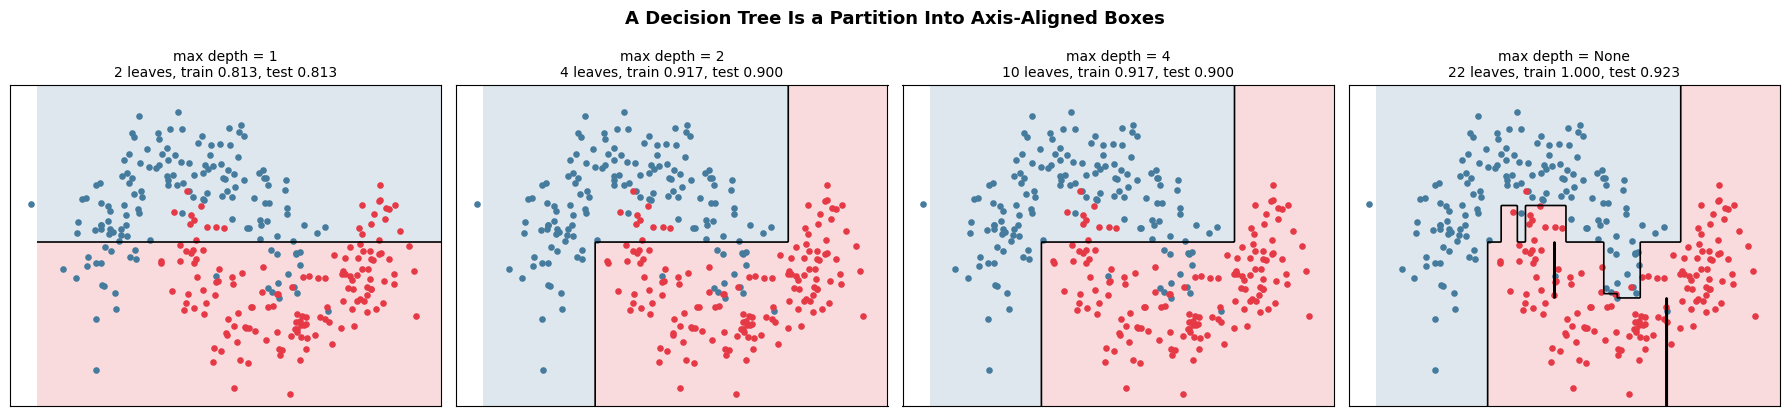

In [2]:
X, y = make_moons(150, 0.25, seed=0)
X_te, y_te = make_moons(2000, 0.25, seed=1)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
print(f"{'depth':>6} {'leaves':>7} {'train acc':>10} {'test acc':>9}")
for ax, depth in zip(axes, [1, 2, 4, None]):
    t = DecisionTree('gini', max_depth=depth).fit(X, y)
    tr, te = np.mean(t.predict(X) == y), np.mean(t.predict(X_te) == y_te)
    plot_regions(ax, t.predict, X, y, f'max depth = {depth}\n{t.n_leaves()} leaves, train {tr:.3f}, test {te:.3f}')
    print(f"{str(depth):>6} {t.n_leaves():>7} {tr:>10.3f} {te:>9.3f}")
plt.suptitle('A Decision Tree Is a Partition Into Axis-Aligned Boxes', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 2. Node Impurity: Misclassification, Entropy, Gini

To decide how to split, we need to measure how mixed a node is. For a node $n$ and class $l\in[k]$, let $p_l(n)$ be the fraction of its training points in class $l$. The three standard **impurity** measures [1, §9.3.3] are

$$
F(n)=\begin{cases}
1-\max_{l}p_l(n) & \text{misclassification}\\[2pt]
-\sum_{l}p_l(n)\log_2p_l(n) & \text{entropy}\\[2pt]
\sum_{l}p_l(n)\big(1-p_l(n)\big) & \text{Gini index}
\end{cases}
$$

A split $q$ sends a fraction $\eta$ of the points of $n$ to the left child $n_-$ and the rest to the right child $n_+$. The **impurity decrease** is

$$\tilde F(n,q)=F(n)-\big[\eta F(n_-)+(1-\eta)F(n_+)\big].$$

**The decrease is never negative.** All three measures are concave functions of the proportion vector $\mathbf{p}$, and $\mathbf{p}(n)=\eta\,\mathbf{p}(n_-)+(1-\eta)\,\mathbf{p}(n_+)$. Jensen's inequality then gives $F(n)\ge\eta F(n_-)+(1-\eta)F(n_+)$.

**Why not simply use misclassification?** It is only piecewise linear, so $\tilde F$ can be exactly zero although the split is clearly useful: this happens whenever the same class stays in the majority in both children. Entropy and Gini are *strictly* concave, so $\tilde F>0$ as soon as the children's proportions differ from the parent's (if they coincide, as in a split that carries no information, the decrease is zero for every measure). They are also differentiable, which is why they are preferred in practice. The two cells of the table below show the classic example: same misclassification decrease, different Gini and entropy decrease.

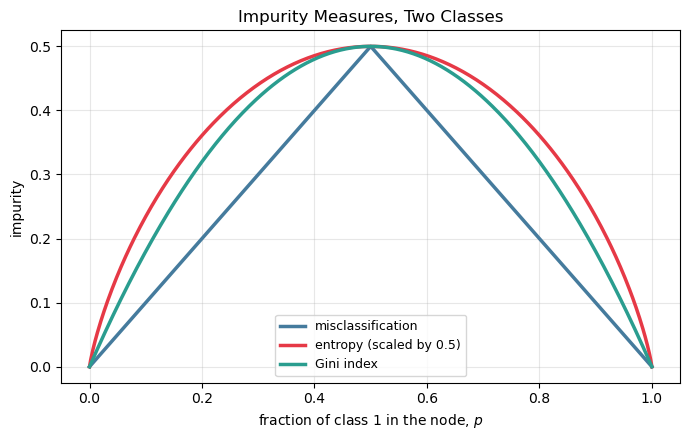

split                         misclass.   entropy     Gini
A: (300,100) | (100,300)         0.2500    0.1887   0.1250
B: (200,400) | (200,  0)         0.2500    0.3113   0.1667

children (40, 10) | (45, 5): misclassification decrease = 0.0000, Gini decrease = 0.0050
min decrease over 100,000 random splits, misclassification : -2.22e-16
min decrease over 100,000 random splits, entropy           : +1.66e-06
min decrease over 100,000 random splits, gini              : +7.57e-07


In [3]:
p = np.linspace(0, 1, 501)
P = np.column_stack([p, 1 - p])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(p, impurity(P, 'misclassification'), color=BLUE, lw=2.5, label='misclassification')
ax.plot(p, 0.5 * impurity(P, 'entropy'), color=RED, lw=2.5, label='entropy (scaled by 0.5)')
ax.plot(p, impurity(P, 'gini'), color=TEAL, lw=2.5, label='Gini index')
ax.set_xlabel('fraction of class 1 in the node, $p$'); ax.set_ylabel('impurity')
ax.set_title('Impurity Measures, Two Classes', fontsize=12); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

def decrease(counts_left, counts_right, criterion):
    L, R = np.array(counts_left, float), np.array(counts_right, float)
    nl, nr = L.sum(), R.sum(); n = nl + nr
    return impurity((L + R) / n, criterion) - (nl / n * impurity(L / nl, criterion) + nr / n * impurity(R / nr, criterion))

# A node with 400 points of each class, and two candidate splits
splits = {'A: (300,100) | (100,300)': ((300, 100), (100, 300)),
          'B: (200,400) | (200,  0)': ((200, 400), (200, 0))}
print(f"{'split':28s} {'misclass.':>10} {'entropy':>9} {'Gini':>8}")
for name, (l, r) in splits.items():
    print(f"{name:28s} {decrease(l, r, 'misclassification'):>10.4f} {decrease(l, r, 'entropy'):>9.4f} {decrease(l, r, 'gini'):>8.4f}")

# Misclassification can see no gain at all: the majority class is the same in both children
l, r = (40, 10), (45, 5)
print(f"\nchildren {l} | {r}: misclassification decrease = {decrease(l, r, 'misclassification'):.4f}, Gini decrease = {decrease(l, r, 'gini'):.4f}")

# Concavity: the decrease is never negative, on 100,000 random splits of random nodes
rng = np.random.default_rng(0)
L, R = rng.integers(1, 200, (100_000, 3)).astype(float), rng.integers(1, 200, (100_000, 3)).astype(float)
for crit in ['misclassification', 'entropy', 'gini']:
    nl, nr = L.sum(1), R.sum(1); n = nl + nr
    d = impurity((L + R) / n[:, None], crit) - (nl / n * impurity(L / nl[:, None], crit) + nr / n * impurity(R / nr[:, None], crit))
    print(f"min decrease over 100,000 random splits, {crit:18s}: {d.min():+.2e}")

---
## 3. Greedy Tree Growing

Finding a decision tree with the smallest error is **NP-hard** [1, §9.3.3], so trees are grown greedily. Start from the root, which holds the whole sample; at each round pick the pair (node, question) with the largest impurity decrease and split there, until the nodes are pure or another stopping rule fires.

**Efficient split search.** For a feature with $n$ points in the node, sort the values once, then scan the $n-1$ possible thresholds. Cumulative sums give the class counts of the left child at every position, so all the thresholds of one feature cost $\mathcal O(n\log n)$. This is what `DecisionTree._best_split` does; thresholds are midpoints between consecutive distinct values. (Growing depth-first, as the code does, yields the same tree as Mohri's best-first rule when the stopping rule depends only on each node, because the split chosen at a node does not depend on the other nodes.)

**The limit of greediness.** A split that looks useless can enable very useful ones. The XOR problem is the classical example: at the root, *no* axis-aligned split decreases the impurity noticeably, yet two levels solve the problem exactly. The code therefore keeps splitting while a node is impure, even when the gain is (almost) zero, which is the behaviour of CART implementations such as scikit-learn's.

XOR: best Gini decrease of any split at the root = 0.0111  (root impurity = 0.4990)


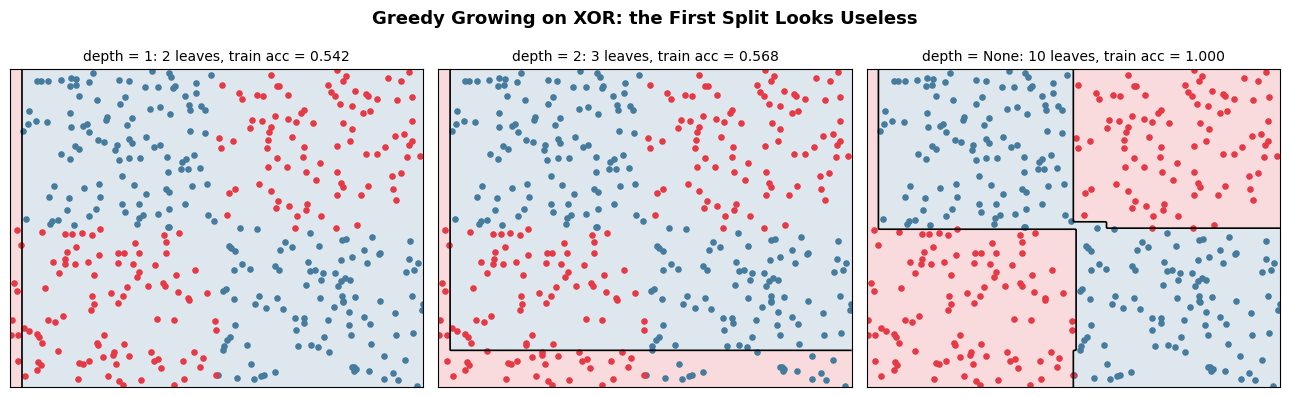

In [4]:
rng = np.random.default_rng(1)
X_xor = rng.uniform(-1, 1, (400, 2))
y_xor = (X_xor[:, 0] * X_xor[:, 1] > 0).astype(int)

root_gain = []
for j in range(2):
    xs = np.sort(X_xor[:, j])
    for thr in (xs[1:] + xs[:-1]) / 2:
        left = X_xor[:, j] <= thr
        root_gain.append(decrease(np.bincount(y_xor[left], minlength=2), np.bincount(y_xor[~left], minlength=2), 'gini'))
print(f"XOR: best Gini decrease of any split at the root = {max(root_gain):.4f}  (root impurity = {impurity(np.bincount(y_xor) / len(y_xor), 'gini'):.4f})")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, depth in zip(axes, [1, 2, None]):
    t = DecisionTree('gini', max_depth=depth).fit(X_xor, y_xor)
    plot_regions(ax, t.predict, X_xor, y_xor, f'depth = {depth}: {t.n_leaves()} leaves, train acc = {np.mean(t.predict(X_xor) == y_xor):.3f}', lim=(-1, 1, -1, 1))
plt.suptitle('Greedy Growing on XOR: the First Split Looks Useless', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 4. Regression Trees

For a real target the leaf predicts the **mean** of its points, and the impurity is the mean squared error, i.e. the variance of the targets in the node [1, footnote 14; 2, §9.2.2]:

$$F(n)=\frac{1}{|n|}\sum_{i\in n}(y_i-\bar y_n)^2,\qquad c_\ell=\bar y_{R_\ell}.$$

The mean is optimal because it minimizes the squared error in each cell, so the tree is a **piecewise-constant** estimator of $\mathbb E[y\mid\mathbf{x}]$. Regression trees matter beyond regression itself: they are the base learner of gradient boosting (Section 14), even for classification.

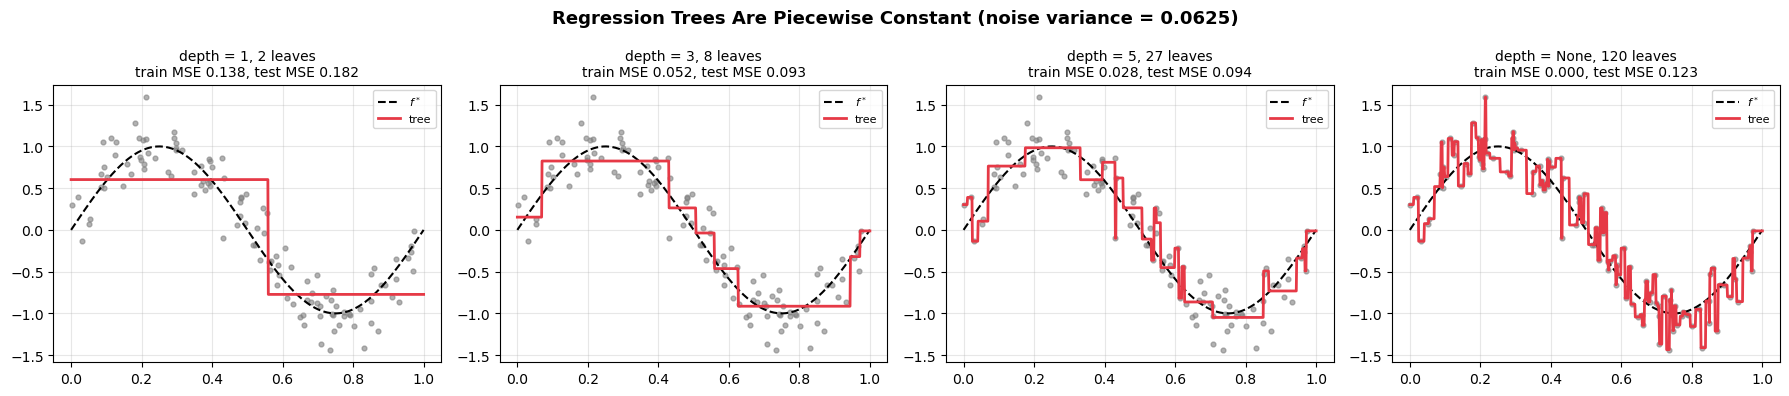

In [5]:
rng = np.random.default_rng(3)
f_true = lambda x: np.sin(2 * np.pi * x)
x_tr = np.sort(rng.uniform(0, 1, 120))[:, None]
y_tr = f_true(x_tr[:, 0]) + rng.normal(0, 0.25, 120)
x_te = rng.uniform(0, 1, 3000)[:, None]
y_te_reg = f_true(x_te[:, 0]) + rng.normal(0, 0.25, 3000)
x_plot = np.linspace(0, 1, 800)[:, None]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, depth in zip(axes, [1, 3, 5, None]):
    t = DecisionTree('mse', max_depth=depth).fit(x_tr, y_tr)
    tr, te = np.mean((t.predict(x_tr) - y_tr)**2), np.mean((t.predict(x_te) - y_te_reg)**2)
    ax.scatter(x_tr[:, 0], y_tr, s=12, color='gray', alpha=0.6)
    ax.plot(x_plot[:, 0], f_true(x_plot[:, 0]), 'k--', lw=1.5, label='$f^*$')
    ax.plot(x_plot[:, 0], t.predict(x_plot), color=RED, lw=2, label='tree')
    ax.set_title(f'depth = {depth}, {t.n_leaves()} leaves\ntrain MSE {tr:.3f}, test MSE {te:.3f}', fontsize=10)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.suptitle('Regression Trees Are Piecewise Constant (noise variance = 0.0625)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 5. Overfitting, Instability and Cost-Complexity Pruning

**Pruning.** Rather than guessing when to stop, grow a large tree and then cut it back [1, §9.3.3; 2, §9.2.2], minimizing the empirical impurity plus a penalty on the number of leaves $|\widetilde{\text{tree}}|$:

$$G_\lambda(\text{tree})=\sum_{n\in\widetilde{\text{tree}}}|n|\,F(n)+\lambda\,|\widetilde{\text{tree}}|\qquad(\text{Mohri et al., eq. 9.15}).$$

**Weakest-link pruning.** Writing $\hat R(\text{tree}')$ for the total impurity of a subtree rooted at an internal node $n'$, collapsing $n'$ into a leaf removes $|\widetilde{\text{tree}'}|-1$ leaves and increases the impurity by $|n'|F(n')-\hat R(\text{tree}')$. So each step collapses the node with the smallest cost per leaf removed,

$$r(n')=\frac{|n'|F(n')-\hat R(\text{tree}')}{|\widetilde{\text{tree}'}|-1},$$

and this yields a finite nested sequence of subtrees containing the optimal $\text{tree}_\lambda$ for every $\lambda$. The value of $\lambda$ is chosen by cross-validation. `pruning_path` in the helper cell uses $\alpha=\lambda/m$, i.e. impurity *fractions* rather than counts, which is scikit-learn's scale. (In the cell below, the Gini index is the impurity, as in scikit-learn; Mohri et al. allow any impurity in $F$.)

**Instability.** Trees "seem relatively easy to interpret [...] however, such interpretations should be carried out with care since decision trees are unstable" [1]: a small change in the training data can change an early split, and hence the whole tree below it. This high variance is the motivation for Part II.

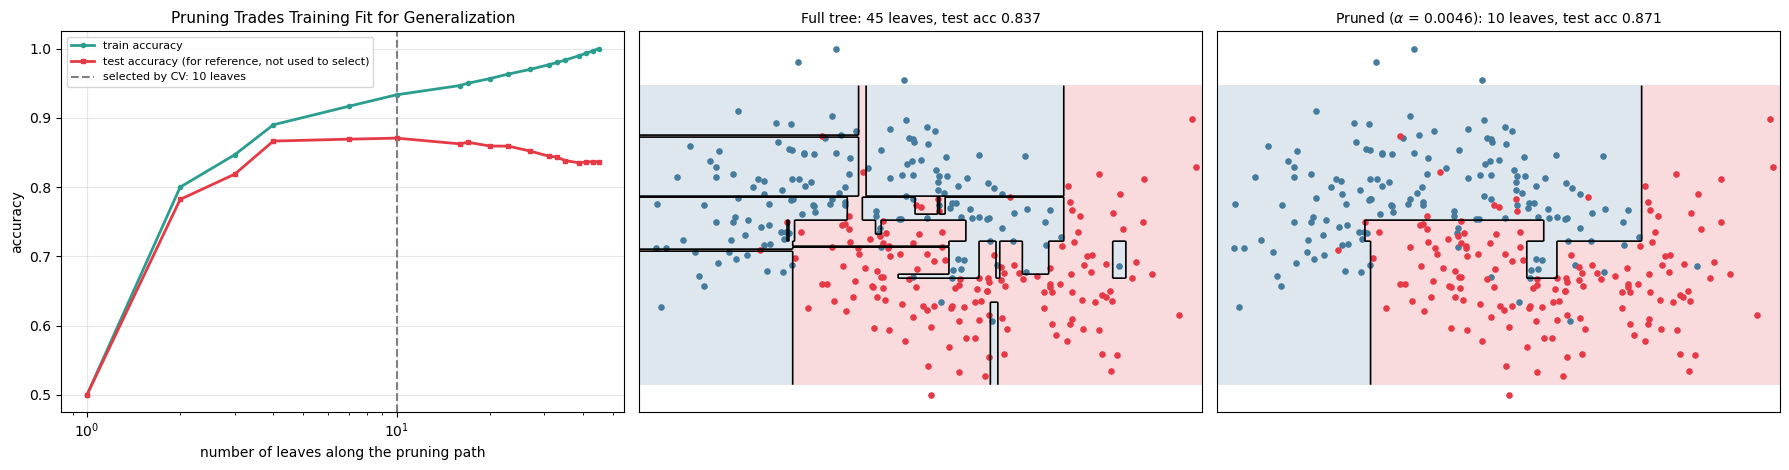

path length: 18 subtrees;  CV chooses alpha = 0.0046  ->  10 leaves
test accuracy: full tree 0.837,  pruned tree 0.871

Instability, removing 5% of the data (30 repetitions): the prediction changes on 2.3% of the input region on average
(feature, threshold) of the root split in the first 8 repetitions: [(1, 0.19), (1, 0.19), (1, 0.19), (1, 0.4), (1, 0.15), (1, 0.19), (1, 0.19), (1, 0.19)]


In [6]:
# Noisy moons: full tree, then the pruning path. Lambda is chosen by 5-fold CV on the training set only.
X, y = make_moons(150, 0.35, seed=2)
X_te, y_te = make_moons(4000, 0.35, seed=3)

full = DecisionTree('gini').fit(X, y)
alphas, masks = pruning_path(full)

def tree_at(tree, alpha_mask):
    tree.collapsed = alpha_mask
    return tree

tr_acc, te_acc, leaves = [], [], []
for mask in masks:
    t = tree_at(full, mask)
    tr_acc.append(np.mean(t.predict(X) == y)); te_acc.append(np.mean(t.predict(X_te) == y_te)); leaves.append(t.n_leaves())
full.collapsed = np.zeros_like(full.collapsed)

grid = np.unique(np.concatenate([[0.0], alphas[:-1] + 1e-9]))
cv = np.zeros((5, len(grid)))
for f, (trn, val) in enumerate(stratified_kfold(y, 5, seed=0)):
    t = DecisionTree('gini').fit(X[trn], y[trn])
    a_f, m_f = pruning_path(t)
    for g, a in enumerate(grid):
        t.collapsed = m_f[np.searchsorted(a_f, a, side='right') - 1]     # the subtree optimal at this alpha
        cv[f, g] = np.mean(t.predict(X[val]) == y[val])
cv_mean, cv_se = cv.mean(axis=0), cv.std(axis=0, ddof=1) / np.sqrt(5)
best = np.argmax(cv_mean)
alpha_cv = grid[best]
idx_cv = np.searchsorted(alphas, alpha_cv, side='right') - 1

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.plot(leaves, tr_acc, color=TEAL, lw=2, marker='o', ms=3, label='train accuracy')
ax.plot(leaves, te_acc, color=RED, lw=2, marker='s', ms=3, label='test accuracy (for reference, not used to select)')
ax.axvline(leaves[idx_cv], color='gray', linestyle='--', label=f'selected by CV: {leaves[idx_cv]} leaves')
ax.set_xlabel('number of leaves along the pruning path'); ax.set_ylabel('accuracy'); ax.set_xscale('log')
ax.set_title('Pruning Trades Training Fit for Generalization', fontsize=11); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plot_regions(axes[1], DecisionTree('gini').fit(X, y).predict, X, y, f'Full tree: {leaves[0]} leaves, test acc {te_acc[0]:.3f}')
full.collapsed = masks[idx_cv]
plot_regions(axes[2], full.predict, X, y, f'Pruned ($\\alpha$ = {alpha_cv:.4f}): {leaves[idx_cv]} leaves, test acc {te_acc[idx_cv]:.3f}')
full.collapsed = np.zeros_like(full.collapsed)
plt.tight_layout(); plt.show()

print(f"path length: {len(alphas)} subtrees;  CV chooses alpha = {alpha_cv:.4f}  ->  {leaves[idx_cv]} leaves")
print(f"test accuracy: full tree {te_acc[0]:.3f},  pruned tree {te_acc[idx_cv]:.3f}")

# Instability: refit after removing 5% of the training points at random
rng = np.random.default_rng(4)
X_grid = rng.uniform([-1.7, -1.2], [2.7, 1.7], (20000, 2))
base = full.predict(X_grid)
disagree, roots = [], []
for r in range(30):
    keep = rng.permutation(len(y))[:int(0.95 * len(y))]
    t = DecisionTree('gini').fit(X[keep], y[keep])
    disagree.append(np.mean(t.predict(X_grid) != base))
    roots.append((int(t.feature[0]), round(float(t.threshold[0]), 2)))
print(f"\nInstability, removing 5% of the data (30 repetitions): the prediction changes on {np.mean(disagree):.1%} of the input region on average")
print(f"(feature, threshold) of the root split in the first 8 repetitions: {roots[:8]}")

---
# Part II — Bagging and Random Forests

---
## 6. Bagging: Averaging Away Variance

**Bootstrap aggregating** (Breiman [5]) trains $B$ models on $B$ bootstrap samples — $N$ points drawn *with replacement* from the training set — and averages them (or takes a majority vote):

$$\hat f_{\text{bag}}(\mathbf{x})=\frac1B\sum_{b=1}^B T_b(\mathbf{x}).$$

**Variance of an average.** Suppose the $B$ trees are identically distributed with variance $\sigma^2$ and pairwise correlation $\rho$. Expanding the variance of the sum,

$$\operatorname{Var}\Big(\frac1B\sum_bT_b\Big)=\frac{1}{B^2}\big[B\sigma^2+B(B-1)\rho\sigma^2\big]=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2\qquad(\text{Hastie et al., eq. 15.1}).$$

As $B\to\infty$ the second term vanishes but the first stays: **correlation between the trees sets the floor**. The expectation of the average equals that of a single tree, so bagging does not change the bias, and the only gain is in variance [2, §15.2]. This is why it helps unstable, low-bias learners such as deep trees, and does little for a stable estimator such as linear regression.

**How much data does a bootstrap sample see?** A given point is missed by one draw with probability $1-\frac1N$, hence by all $N$ draws with probability

$$\Big(1-\frac1N\Big)^N\xrightarrow[N\to\infty]{}\frac1e\approx0.368.$$

So each tree is trained on about 63.2% of the distinct points, and the remaining 36.8% are **out-of-bag** for that tree (Section 8).

N =     10: out-of-bag fraction = 0.3455   (1 - 1/N)^N = 0.3487   1/e = 0.3679
N =    100: out-of-bag fraction = 0.3650   (1 - 1/N)^N = 0.3660   1/e = 0.3679
N =  10000: out-of-bag fraction = 0.3681   (1 - 1/N)^N = 0.3679   1/e = 0.3679

Bias^2 and variance at fixed x, averaged over x (60 independent training sets of 80 points)
         model    Bias^2   Variance
          tree    0.0009     0.0880
   bagged tree    0.0005     0.0422
         cubic    0.0038     0.0043
  bagged cubic    0.0037     0.0045


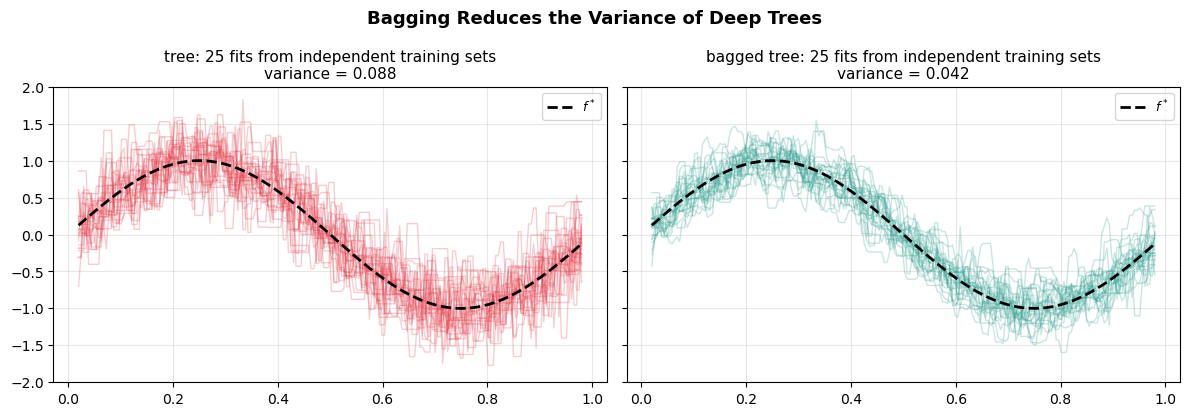

In [7]:
# (a) Fraction of points out of bag
rng = np.random.default_rng(0)
for n_pts in [10, 100, 10_000]:
    frac = np.mean([1 - len(np.unique(rng.integers(n_pts, size=n_pts))) / n_pts for _ in range(2000 if n_pts < 10_000 else 200)])
    print(f"N = {n_pts:>6}: out-of-bag fraction = {frac:.4f}   (1 - 1/N)^N = {(1 - 1/n_pts)**n_pts:.4f}   1/e = {np.exp(-1):.4f}")

# (b) Bagging deep trees vs bagging a stable learner, on independent training sets
f_true2 = lambda x: np.sin(2 * np.pi * x)
x_grid = np.linspace(0.02, 0.98, 200)[:, None]
n_sets, n_pts, B_bag = 60, 80, 40

def fit_poly3(x, y):
    w = np.linalg.lstsq(np.vander(x[:, 0], 4), y, rcond=None)[0]
    return lambda xq: np.vander(xq[:, 0], 4) @ w
def fit_tree(x, y):
    return DecisionTree('mse', seed=0).fit(x, y).predict

rng = np.random.default_rng(1)
preds = {k: [] for k in ['tree', 'bagged tree', 'cubic', 'bagged cubic']}
for s in range(n_sets):
    x = rng.uniform(0, 1, n_pts)[:, None]
    y = f_true2(x[:, 0]) + rng.normal(0, 0.3, n_pts)
    preds['tree'].append(fit_tree(x, y)(x_grid))
    preds['cubic'].append(fit_poly3(x, y)(x_grid))
    bt, bc = [], []
    for b in range(B_bag):
        i = rng.integers(n_pts, size=n_pts)
        bt.append(fit_tree(x[i], y[i])(x_grid)); bc.append(fit_poly3(x[i], y[i])(x_grid))
    preds['bagged tree'].append(np.mean(bt, axis=0)); preds['bagged cubic'].append(np.mean(bc, axis=0))

print(f"\nBias^2 and variance at fixed x, averaged over x ({n_sets} independent training sets of {n_pts} points)")
print(f"{'model':>14} {'Bias^2':>9} {'Variance':>10}")
truth = f_true2(x_grid[:, 0])
stats = {}
for k, v in preds.items():
    v = np.array(v)
    stats[k] = (np.mean((v.mean(axis=0) - truth)**2), np.mean(v.var(axis=0)))
    print(f"{k:>14} {stats[k][0]:>9.4f} {stats[k][1]:>10.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, k, c in zip(axes, ['tree', 'bagged tree'], [RED, TEAL]):
    for row in np.array(preds[k])[:25]:
        ax.plot(x_grid[:, 0], row, color=c, alpha=0.25, lw=1)
    ax.plot(x_grid[:, 0], truth, 'k--', lw=2, label='$f^*$')
    ax.set_title(f'{k}: 25 fits from independent training sets\nvariance = {stats[k][1]:.3f}', fontsize=11); ax.set_ylim(-2, 2)
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.suptitle('Bagging Reduces the Variance of Deep Trees', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 7. Random Forests: Decorrelating the Trees

Trees grown on bootstrap samples of the same data are still strongly correlated: a dominant feature tends to be chosen near the top of all of them. **Random forests** (Breiman [5]; Hastie et al. [2], Alg. 15.1) attack the term $\rho\sigma^2$ directly:

1. For $b=1,\dots,B$: draw a bootstrap sample and grow a tree on it. **Before each split**, select $m\le d$ features at random and pick the best split among those only.
2. Predict by averaging (regression) or by majority vote (classification).

The usual defaults are $m=\lfloor\sqrt d\rfloor$ for classification and $m=\lfloor d/3\rfloor$ for regression; $m=d$ is plain bagging. Reducing $m$ reduces the correlation between trees, but each tree becomes individually weaker and more variable, so the best $m$ is a compromise, to be chosen by validation.

The class `RandomForest` of the helper cell averages the **class probabilities** of the trees rather than their hard votes (this is scikit-learn's convention; Breiman's original forest uses majority vote; the two usually behave similarly).

Below we measure $\rho$ and $\sigma^2$ directly, for a regression problem and several values of $m$, on many independent training sets, and compare the measured variance of the forest with formula (15.1).

40 training sets of 150 points, B = 20 trees per forest

  m |    rho  sigma^2 | Var (measured)  rho s2 + (1-rho) s2 / B
  1 |  0.033   15.641 |          1.246                    1.258
  3 |  0.045   13.778 |          1.375                    1.247
  5 |  0.079   12.116 |          1.447                    1.508
 10 |  0.130   10.541 |          1.751                    1.829


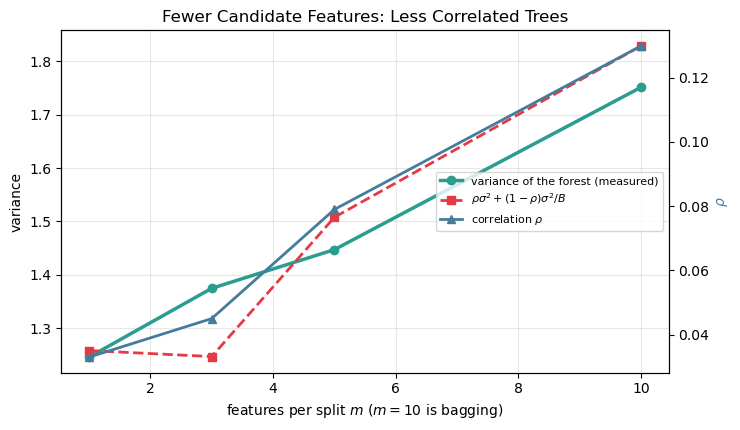

In [8]:
# Friedman-style regression target: 5 relevant features out of 10
def sample_reg(n, rng):
    X = rng.uniform(0, 1, (n, 10))
    y = 10*np.sin(np.pi*X[:, 0]*X[:, 1]) + 20*(X[:, 2] - 0.5)**2 + 10*X[:, 3] + 5*X[:, 4] + rng.normal(0, 1, n)
    return X, y

rng = np.random.default_rng(0)
X_q, _ = sample_reg(200, rng)              # fixed query points
n_sets, n_pts, B = 40, 150, 20
print(f"{n_sets} training sets of {n_pts} points, B = {B} trees per forest\n")
print(f"{'m':>3} | {'rho':>6} {'sigma^2':>8} | {'Var (measured)':>14} {'rho s2 + (1-rho) s2 / B':>24}")
rows = []
for m_try in [1, 3, 5, 10]:
    T_all = np.zeros((n_sets, B, len(X_q)))
    for s in range(n_sets):
        X_s, y_s = sample_reg(n_pts, rng)
        forest = RandomForest(B=B, max_features=m_try, criterion='mse', min_samples_leaf=3, seed=int(rng.integers(2**31))).fit(X_s, y_s)
        for b, t in enumerate(forest.trees):
            T_all[s, b] = t.predict(X_q)
    # sigma^2(x): variance of one tree over training sets and randomness; rho(x): correlation of two trees
    sig2 = T_all.reshape(-1, len(X_q)).var(axis=0)
    a, b_ = T_all[:, ::2, :], T_all[:, 1::2, :]
    cov = np.mean((a - T_all.mean(axis=(0, 1))) * (b_ - T_all.mean(axis=(0, 1))), axis=(0, 1))
    rho = cov / sig2
    var_forest = T_all.mean(axis=1).var(axis=0)
    rows.append((m_try, rho.mean(), sig2.mean(), var_forest.mean(), np.mean(rho * sig2 + (1 - rho) * sig2 / B)))
    print(f"{m_try:>3} | {rows[-1][1]:>6.3f} {rows[-1][2]:>8.3f} | {rows[-1][3]:>14.3f} {rows[-1][4]:>24.3f}")
rows = np.array(rows)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.plot(rows[:, 0], rows[:, 3], color=TEAL, lw=2.5, marker='o', label='variance of the forest (measured)')
ax.plot(rows[:, 0], rows[:, 4], color=RED, lw=2, linestyle='--', marker='s', label=r'$\rho\sigma^2+(1-\rho)\sigma^2/B$')
ax2 = ax.twinx()
ax2.plot(rows[:, 0], rows[:, 1], color=BLUE, lw=2, marker='^', label=r'correlation $\rho$')
ax2.set_ylabel(r'$\rho$', color=BLUE); ax.set_xlabel('features per split $m$ ($m=10$ is bagging)'); ax.set_ylabel('variance')
ax.set_title('Fewer Candidate Features: Less Correlated Trees', fontsize=12)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='center right'); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
## 8. Out-of-Bag Error and Feature Importance

**Out-of-bag (OOB) error.** Each point is out of bag for about 37% of the trees. Predict it using those trees only, and average the error over the training set: this estimates the test error **without a validation set** and without refitting, and it is close to leave-one-out-style cross-validation once $B$ is large [2, §15.3.1].

**Feature importance.** Two common measures:

* **Impurity-based:** total decrease of impurity from all the splits on a feature, averaged over trees. It is cheap, but it is computed on the training data and it is known to favour features with many distinct values.
* **Permutation:** shuffle one feature on held-out data and record the drop in accuracy. It measures what the model actually uses, but correlated features can hide each other: if two features carry the same information, shuffling one costs little.

The experiment below uses a real dataset (breast cancer, 30 features) and adds one pure-noise feature with many distinct values as a control.

OOB error (no held-out data used) = 0.0501
test error                         = 0.0412   (170 test points; one point = 0.0059)


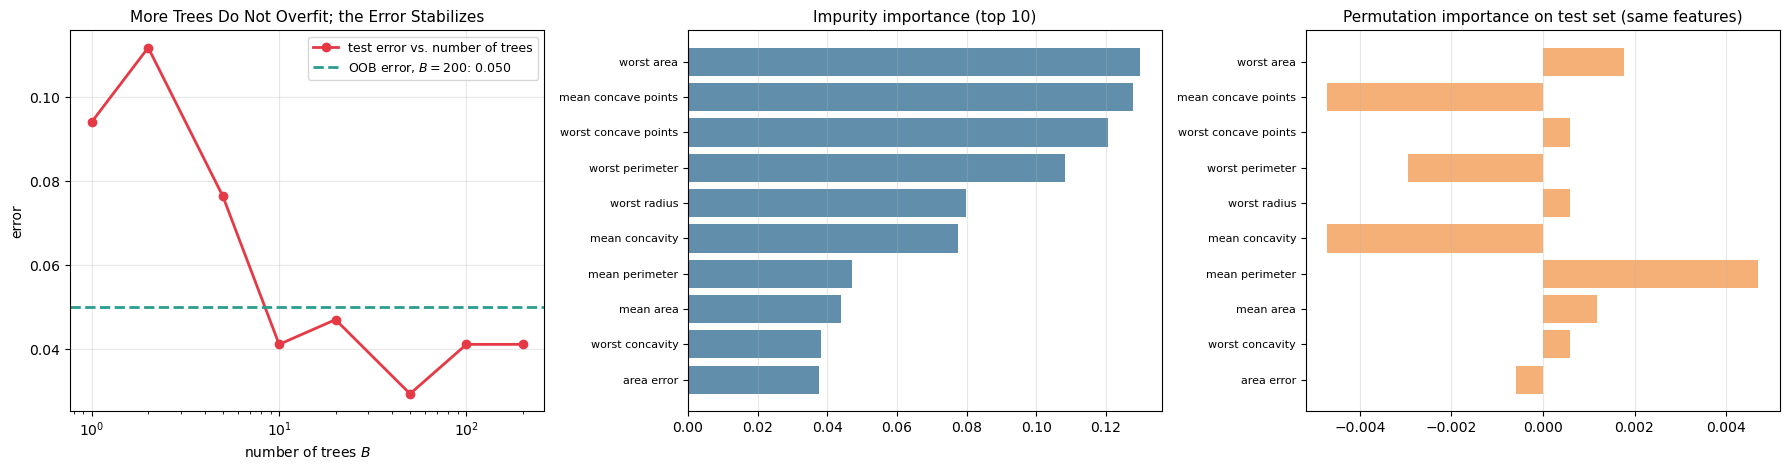


NOISE control: impurity importance rank 31 of 31,  permutation importance = -0.0018
features with permutation importance > 0: 20 of 31


In [9]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
rng = np.random.default_rng(0)
X_bc = np.column_stack([data.data, rng.normal(size=len(data.data))])     # last column: pure noise
names_bc = list(data.feature_names) + ['NOISE (control)']
y_bc = data.target
X_tr, X_te, y_tr, y_te = train_test_split_np(X_bc, y_bc, 0.3, seed=0)

forest = RandomForest(B=200, seed=0).fit(X_tr, y_tr)
Bs = [1, 2, 5, 10, 20, 50, 100, 200]
test_err = [np.mean(forest.predict(X_te, n_trees=b) != y_te) for b in Bs]
print(f"OOB error (no held-out data used) = {forest.oob_score_:.4f}")
print(f"test error                         = {test_err[-1]:.4f}   ({len(y_te)} test points; one point = {1/len(y_te):.4f})")

# Impurity importance: walk over the nodes of every tree
imp = np.zeros(X_bc.shape[1])
for t in forest.trees:
    for n in np.where(t.left >= 0)[0]:
        a, b = t.left[n], t.right[n]
        imp[t.feature[n]] += (t.n_node[n] * t.imp[n] - t.n_node[a] * t.imp[a] - t.n_node[b] * t.imp[b]) / t.n_node[0]
imp /= imp.sum()

# Permutation importance on the test set
base_acc, perm_imp = np.mean(forest.predict(X_te) == y_te), np.zeros(X_bc.shape[1])
for j in range(X_bc.shape[1]):
    drops = []
    for r in range(10):
        X_p = X_te.copy(); X_p[:, j] = rng.permutation(X_p[:, j])
        drops.append(base_acc - np.mean(forest.predict(X_p) == y_te))
    perm_imp[j] = np.mean(drops)

top = np.argsort(imp)[::-1][:10]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].semilogx(Bs, test_err, color=RED, lw=2, marker='o', label='test error vs. number of trees')
axes[0].axhline(forest.oob_score_, color=TEAL, lw=2, linestyle='--', label=f'OOB error, $B=200$: {forest.oob_score_:.3f}')
axes[0].set_xlabel('number of trees $B$'); axes[0].set_ylabel('error'); axes[0].set_title('More Trees Do Not Overfit; the Error Stabilizes', fontsize=11)
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
for ax, vals, title, c in [(axes[1], imp, 'Impurity importance (top 10)', BLUE), (axes[2], perm_imp, 'Permutation importance on test set (same features)', ORANGE)]:
    ax.barh(range(10), vals[top][::-1], color=c, alpha=0.85)
    ax.set_yticks(range(10)); ax.set_yticklabels([names_bc[j] for j in top[::-1]], fontsize=8)
    ax.set_title(title, fontsize=11); ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout(); plt.show()

print(f"\nNOISE control: impurity importance rank {int(np.where(np.argsort(imp)[::-1] == X_bc.shape[1]-1)[0][0]) + 1} of {X_bc.shape[1]},  permutation importance = {perm_imp[-1]:+.4f}")
print(f"features with permutation importance > 0: {int(np.sum(perm_imp > 0))} of {X_bc.shape[1]}")

---
# Part III — Boosting

We follow Mohri et al. [1], Ch. 7 and §9.3.2. **Setting:** a sample $S=((x_1,y_1),\dots,(x_m,y_m))\in(\mathcal X\times\mathcal Y)^m$, labels $y_i\in\{-1,+1\}$, and a set $\mathcal H$ of base classifiers $h:\mathcal X\to\{-1,+1\}$.

---
## 9. Weak Learning and AdaBoost

A **weak learner** is only guaranteed to do slightly better than random: for some $\gamma>0$ and every distribution, it returns (with high probability) a hypothesis with error at most $\frac12-\gamma$ [1, Def. 7.1]. Compare with the PAC definition of `02`, §1.2, where $\epsilon$ can be arbitrarily small. Boosting answers the question: *can weak learners be combined into a strong one?*

**The key device.** AdaBoost defines, on purpose, for every round $t\in[T]$, **a distribution $D_t$ over the indices $\{1,\dots,m\}$** of the training points, and asks for a base classifier with small error **with respect to $D_t$**:

$$\epsilon_t=\Pr_{i\sim D_t}\big[h_t(x_i)\neq y_i\big]=\sum_{i=1}^mD_t(i)\,\mathbb 1[h_t(x_i)\neq y_i].$$

**Algorithm** ([1], Fig. 7.1). $D_1(i)=\frac1m$. For $t=1,\dots,T$:

1. $h_t\in\mathcal H$ with small error $\epsilon_t$ under $D_t$;
2. $\alpha_t=\frac12\log\frac{1-\epsilon_t}{\epsilon_t}$;
3. $Z_t=2\sqrt{\epsilon_t(1-\epsilon_t)}$ (normalization factor);
4. $D_{t+1}(i)=\dfrac{D_t(i)\,\exp(-\alpha_ty_ih_t(x_i))}{Z_t}$.

Output $f=\sum_{t=1}^T\alpha_th_t$, classifying by $\operatorname{sgn}(f)$.

If $\epsilon_t<\frac12$ then $\alpha_t>0$: misclassified points ($y_ih_t(x_i)=-1$) gain weight, correctly classified ones lose weight, so the next base classifier concentrates on what is still wrong. Expanding the recursion gives the identity

$$D_{t+1}(i)=\frac{e^{-y_if_t(x_i)}}{m\prod_{s=1}^tZ_s}\qquad(\text{Mohri et al., eq. 7.2}),\qquad f_t=\sum_{s=1}^t\alpha_sh_s.$$

**Base classifiers.** We use **decision stumps**, the trees of depth 1 of Part I: $h(x)=\pm\operatorname{sgn}(x_j-\theta)$. On a training set the set of distinct stumps is finite, as `StumpPool` makes explicit, and `adaboost` selects the stump with the *smallest weighted error*.

m = 200 points, |H| = 2 x 398 = 796 stumps
identity (7.2): D_6(i) = exp(-y_i f_5(x_i)) / (m Z_1...Z_5): False


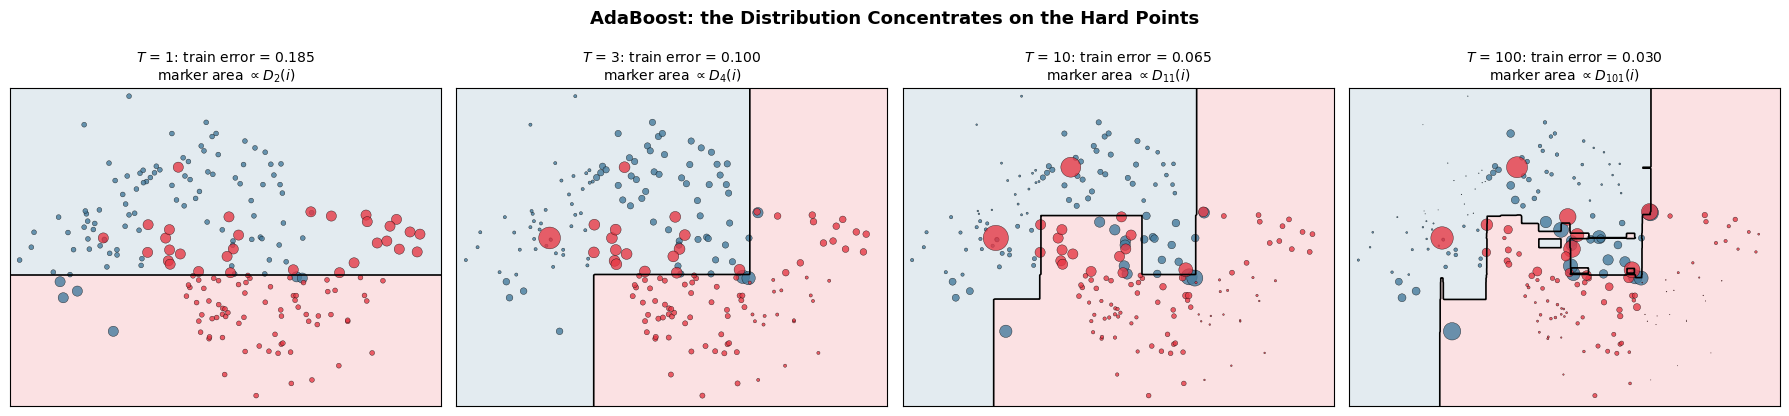

In [10]:
X, y01 = make_moons(100, 0.3, seed=5)
y = 2.0 * y01 - 1
pool = StumpPool(X)
Phi = pool.phi(X)
print(f"m = {len(y)} points, |H| = 2 x {Phi.shape[1]} = {2*Phi.shape[1]} stumps")

model = adaboost(Phi, y, 200)
F_stage = staged_scores(model, Phi[:, model['k']])
D_check = np.exp(-y[:, None] * F_stage[:, 4]) / (len(y) * np.prod(model['Z'][:5]))
D_run = np.full(len(y), 1 / len(y))
for t in range(5):
    D_run = D_run * np.exp(-model['alpha'][t] * y * model['s'][t] * Phi[:, model['k'][t]]) / model['Z'][t]
print("identity (7.2): D_6(i) = exp(-y_i f_5(x_i)) / (m Z_1...Z_5):", np.allclose(D_run, D_check[:, ] if D_check.ndim == 1 else D_check))

# Weights and boundary after a few rounds: marker area proportional to D_t
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
xx, yy = np.meshgrid(np.linspace(-1.7, 2.7, 300), np.linspace(-1.3, 1.8, 300))
grid = np.column_stack([xx.ravel(), yy.ravel()])
Phi_g = pool.phi(grid, model['k'])
for ax, t_show in zip(axes, [1, 3, 10, 100]):
    D = np.full(len(y), 1 / len(y))
    for t in range(t_show):
        D = D * np.exp(-model['alpha'][t] * y * model['s'][t] * Phi[:, model['k'][t]]) / model['Z'][t]
    F = (Phi_g[:, :t_show] * (model['alpha'][:t_show] * model['s'][:t_show])).sum(axis=1).reshape(xx.shape)
    ax.contourf(xx, yy, F, levels=[-1e9, 0, 1e9], colors=[BLUE, RED], alpha=0.15)
    ax.contour(xx, yy, F, levels=[0], colors='k', linewidths=1.2)
    ax.scatter(*X[y < 0].T, s=4000 * D[y < 0], color=BLUE, edgecolor='k', lw=0.3, alpha=0.8)
    ax.scatter(*X[y > 0].T, s=4000 * D[y > 0], color=RED, edgecolor='k', lw=0.3, alpha=0.8)
    err = np.mean(np.sign(F_stage[:, t_show - 1]) != y)
    ax.set_title(f'$T$ = {t_show}: train error = {err:.3f}\nmarker area $\\propto D_{{{t_show + 1}}}(i)$', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('AdaBoost: the Distribution Concentrates on the Hard Points', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
## 10. The Empirical Error Decreases Exponentially

**Theorem 7.2** [1]. *The empirical error of the classifier returned by AdaBoost satisfies*

$$\hat R_S(f)\le\exp\Big[-2\sum_{t=1}^T\big(\tfrac12-\epsilon_t\big)^2\Big],$$

*and if $\frac12-\epsilon_t\ge\gamma$ for all $t$, then $\hat R_S(f)\le\exp(-2\gamma^2T)$.*

**Proof.** Since $\mathbb 1_{u\le0}\le e^{-u}$ for all $u$, and by identity (7.2),

$$\hat R_S(f)=\frac1m\sum_i\mathbb 1_{y_if(x_i)\le0}\le\frac1m\sum_ie^{-y_if(x_i)}=\frac1m\sum_i\Big[m\prod_{t=1}^TZ_t\Big]D_{T+1}(i)=\prod_{t=1}^TZ_t,$$

because $D_{T+1}$ sums to one. Each normalization factor is

$$Z_t=\sum_iD_t(i)e^{-\alpha_ty_ih_t(x_i)}=(1-\epsilon_t)e^{-\alpha_t}+\epsilon_te^{\alpha_t}=2\sqrt{\epsilon_t(1-\epsilon_t)}=\sqrt{1-4\big(\tfrac12-\epsilon_t\big)^2}\le\exp\big[-2\big(\tfrac12-\epsilon_t\big)^2\big],$$

using $1-x\le e^{-x}$. Multiplying over $t$ gives the claim. $\blacksquare$

**Three remarks.**

* **Where $\alpha_t$ comes from.** $\alpha_t$ is exactly the minimizer of $\phi(\alpha)=(1-\epsilon_t)e^{-\alpha}+\epsilon_te^{\alpha}$: it minimizes $Z_t$, hence greedily minimizes the upper bound $\prod_tZ_t$.
* **Adaptive.** Neither $\gamma$ nor the accuracy of the base classifiers has to be known in advance: this is the *adaptive* in AdaBoost.
* **Equalized mass.** The optimality condition $(1-\epsilon_t)e^{-\alpha_t}=\epsilon_te^{\alpha_t}$ means that after each update the correctly and the incorrectly classified points have **equal total mass** $\frac12$. So $h_t$ has error exactly $\frac12$ under $D_{t+1}$: the next round must find something new.

---
## 11. The Exponential Loss and AdaBoost as Coordinate Descent

**Remember:** we use the exponential loss because it is an **upper bound on the zero-one loss**, $\mathbb 1_{u\le0}\le e^{-u}$, and it is convex and differentiable. Assume $\mathcal H=\{h_1,\dots,h_N\}$ finite. An ensemble is $f=\sum_{j=1}^N\bar\alpha_jh_j$, and **$\bar{\boldsymbol\alpha}$ is the vector of weights, one coordinate per base classifier**. Define the objective, for all $\bar{\boldsymbol\alpha}\in\mathbb R^N$,

$$F(\bar{\boldsymbol\alpha})=\frac1m\sum_{i=1}^me^{-y_if(x_i)}=\frac1m\sum_{i=1}^me^{-y_i\sum_{j=1}^N\bar\alpha_jh_j(x_i)}\ \ge\ \hat R_S(f)\qquad(\text{Mohri et al., eqs. 7.6–7.7}).$$

$F$ is convex (a sum of exponentials of affine functions of $\bar{\boldsymbol\alpha}$) and differentiable.

**Coordinate descent on $F$.** Start at $\bar{\boldsymbol\alpha}_0=\mathbf 0$. At each round pick the maximum descent direction $\mathbf e_k$, then the best step $\eta$ along it. Define, **on purpose, for every $t\in[T]$, a distribution over the indices $\{1,\dots,m\}$**:

$$\bar D_t(i)=\frac{e^{-y_i\bar g_{t-1}(x_i)}}{\bar Z_t},\qquad\bar g_{t-1}=\sum_j\bar\alpha_{t-1,j}h_j,\qquad\bar Z_t=\sum_{i}e^{-y_i\bar g_{t-1}(x_i)}.$$

**Direction.** With $\bar\epsilon_{t,k}=\Pr_{i\sim\bar D_t}[y_ih_k(x_i)\le0]$, the directional derivative along $\mathbf e_k$ is

$$F'(\bar{\boldsymbol\alpha}_{t-1},\mathbf e_k)=-\frac1m\sum_iy_ih_k(x_i)e^{-y_i\bar g_{t-1}(x_i)}=-\big[(1-\bar\epsilon_{t,k})-\bar\epsilon_{t,k}\big]\frac{\bar Z_t}{m}=\big[2\bar\epsilon_{t,k}-1\big]\frac{\bar Z_t}{m}.$$

$\bar Z_t/m$ does not depend on $k$, so the steepest direction is the $k$ with the **smallest weighted error**: exactly AdaBoost's choice of $h_t$.

**Step.** Setting $\frac{d}{d\eta}F(\bar{\boldsymbol\alpha}_{t-1}+\eta\mathbf e_k)=0$ gives $-[(1-\bar\epsilon_{t,k})e^{-\eta}-\bar\epsilon_{t,k}e^{\eta}]=0$, i.e.

$$\eta=\frac12\log\frac{1-\bar\epsilon_{t,k}}{\bar\epsilon_{t,k}}:$$

exactly AdaBoost's $\alpha_t$. By induction $\bar g_t=f_t$ and $\bar D_t=D_t$.

> **Remark.** AdaBoost coincides exactly with the application of coordinate descent to the objective function $F$. $F$ is the objective that AdaBoost seeks to minimize.

**The experiment.** `coordinate_descent` below contains *no AdaBoost formula*: it computes all the derivatives of $F$ explicitly and finds the step with a generic numerical line search. Then we compare it with `adaboost`, round by round.

**Other losses.** The same recipe applies to any convex differentiable upper bound of the zero-one loss. Replacing $e^{-u}$ with the logistic loss $\log_2(1+e^{-u})$ gives an objective that coincides with logistic regression (`07`) on the base-classifier features.

In [ ]:
# Same data as Section 9; H contains each stump and its negation explicitly
H = np.hstack([Phi, -Phi]).astype(float)
T_cd = 60
picks, steps, F_cd = coordinate_descent(H, y, T_cd)
model_cd = adaboost(Phi, y, T_cd)

hyp_ada = (model_cd['s'][:, None] * Phi[:, model_cd['k']].T)            # h_t on the sample, as chosen by AdaBoost
hyp_cd = H[:, picks].T
F_ada = np.mean(np.exp(-y * np.cumsum(model_cd['alpha'][:, None] * hyp_ada, axis=0)), axis=1)

print(f"Round-by-round comparison over T = {T_cd} rounds:")
print(f"  same h_t in every round          : {np.array_equal(hyp_ada, hyp_cd)}")
print(f"  step eta_t = alpha_t             : {np.allclose(steps, model_cd['alpha'], atol=1e-5)}   (max |diff| = {np.abs(steps - model_cd['alpha']).max():.1e})")
print(f"  F along the two trajectories     : {np.allclose(F_cd, F_ada, atol=1e-8)}   (max |diff| = {np.abs(F_cd - F_ada).max():.1e})")

u = np.linspace(-2, 2.5, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.plot(u, (u <= 0).astype(float), 'k', lw=2, label='zero-one $\\mathbb{1}_{u\\leq 0}$')
ax.plot(u, np.exp(-u), color=RED, lw=2.5, label='exponential $e^{-u}$ (AdaBoost)')
ax.plot(u, np.log2(1 + np.exp(-u)), color=TEAL, lw=2.5, label='logistic $\\log_2(1+e^{-u})$ (`07`)')
ax.plot(u, np.maximum(0, 1 - u), color=BLUE, lw=2.5, label='hinge $\\max(0,1-u)$ (`08`)')
ax.set_ylim(-0.1, 5); ax.set_xlabel('margin $u = y f(x)$'); ax.set_ylabel('loss')
ax.set_title('Convex Upper Bounds on the Zero-One Loss', fontsize=11); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
ax = axes[1]
ax.plot(np.arange(1, T_cd + 1), F_ada, color=RED, lw=4, alpha=0.45, label='AdaBoost: $F(\\alpha_t) = \\prod_s Z_s$')
ax.plot(np.arange(1, T_cd + 1), F_cd, 'k--', lw=1.5, label='coordinate descent + line search')
ax.set_xlabel('round $t$'); ax.set_ylabel('$F$'); ax.set_title('Two Algorithms, One Trajectory', fontsize=11)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
## 12. Margins: Why the Test Error Can Keep Improving

The complexity of $T$-round ensembles grows with $T$ ([1], eq. 7.9: $\operatorname{VCdim}\le2(d+1)(T+1)\log_2((T+1)e)$), so AdaBoost *can* overfit, and it does in some cases. Yet it has often been observed that the test error keeps decreasing after the training error reaches zero. The VC bound cannot explain this; a **margin** analysis can.

For $f=\sum_t\alpha_th_t$ with $\alpha_t\ge0$, the normalized function $\bar f=f/\|\boldsymbol\alpha\|_1$ lies in the convex hull $\operatorname{conv}(\mathcal H)$, and $y\bar f(x)\in[-1,1]$ is the $L_1$ **confidence margin** of $(x,y)$ [1, Def. 7.3]. Taking convex combinations does not increase Rademacher complexity (Lemma 7.4), so for any fixed $\rho>0$, with probability at least $1-\delta$ [1, eq. 7.16],

$$R(f)\le\hat R_{S,\rho}(\bar f)+\frac2\rho\mathfrak R_m(\mathcal H)+\sqrt{\frac{\log\frac1\delta}{2m}}.$$

**The number of rounds $T$ does not appear.** Even at zero training error, further rounds can keep raising the small margins, which can reduce the first term. This explains the phenomenon as far as a bound can: it is an upper bound, so it does not *guarantee* that the test error decreases at every round.

**Noise.** The exponential loss grows very fast for negative margins, so mislabeled points receive exponentially large weights. AdaBoost is therefore sensitive to label noise; the logistic loss, which grows only linearly (`01`, §3.4), is more robust. The second experiment below measures this effect with stumps.

In [ ]:
from sklearn.datasets import load_breast_cancer
X_all, y_all = load_breast_cancer(return_X_y=True)
y_all = 2.0 * y_all - 1
X_tr, X_te, y_tr, y_te = train_test_split_np(X_all, y_all, 0.3, seed=0)

pool_bc = StumpPool(X_tr)
Phi_tr = pool_bc.phi(X_tr)
T = 1000
m_bc = adaboost(Phi_tr, y_tr, T)
T = len(m_bc['alpha'])
F_tr = staged_scores(m_bc, Phi_tr[:, m_bc['k']])
F_te = staged_scores(m_bc, pool_bc.phi(X_te, m_bc['k']))
tr_err, te_err = np.mean(np.sign(F_tr) != y_tr[:, None], axis=0), np.mean(np.sign(F_te) != y_te[:, None], axis=0)
l1 = np.cumsum(m_bc['alpha'])
margins = y_tr[:, None] * F_tr / l1

first_zero = int(np.argmax(tr_err == 0)) + 1 if np.any(tr_err == 0) else None
print(f"breast cancer: {Phi_tr.shape[1]} stumps, {len(y_tr)} training and {len(y_te)} test points; one test point = {1/len(y_te):.4f}")
print(f"training error reaches 0 at T = {first_zero}")
for t in [first_zero, 200, 500, T]:
    if t is not None:
        print(f"  T = {t:>4}: train error {tr_err[t-1]:.4f}, test error {te_err[t-1]:.4f}, smallest margin {margins[:, t-1].min():+.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.semilogx(np.arange(1, T + 1), tr_err, color=TEAL, lw=2, label='train error')
ax.semilogx(np.arange(1, T + 1), te_err, color=RED, lw=2, label='test error')
if first_zero: ax.axvline(first_zero, color='gray', linestyle='--', label=f'train error = 0 at $T$ = {first_zero}')
ax.set_xlabel('rounds $T$'); ax.set_ylabel('error'); ax.set_title('Breast Cancer: Error vs. Rounds', fontsize=11); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
ax = axes[1]
for t, c in zip([10, 100, T], [ORANGE, BLUE, RED]):
    ax.plot(np.sort(margins[:, t - 1]), np.linspace(0, 1, len(y_tr)), color=c, lw=2, label=f'$T$ = {t}')
ax.axvline(0, color='gray', lw=1); ax.set_xlabel(r'margin $y\bar f(x)$'); ax.set_ylabel('cumulative fraction of training points')
ax.set_title('The Margin Distribution Keeps Moving Right', fontsize=11); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

# Label noise: flip a fraction of the TRAINING labels; compare AdaBoost and logistic gradient boosting with stumps
noise_levels, reps = [0.0, 0.1, 0.2, 0.3], 5
res = {'AdaBoost (exponential)': [], 'Gradient boosting (logistic)': []}
for noise in noise_levels:
    a_err, g_err = [], []
    for r in range(reps):
        rng = np.random.default_rng(100 + r)
        Xa, Xb, ya, yb = train_test_split_np(X_all, y_all, 0.3, seed=100 + r)
        ya = ya.copy()
        flip = rng.choice(len(ya), int(noise * len(ya)), replace=False); ya[flip] = -ya[flip]
        pool_n = StumpPool(Xa)
        m_n = adaboost(pool_n.phi(Xa), ya, 300)
        a_err.append(np.mean(np.sign(staged_scores(m_n, pool_n.phi(Xb, m_n['k']))[:, -1]) != yb))
        gb = GradientBoosting('logistic', n_estimators=300, lr=0.1, max_depth=1).fit(Xa, (ya > 0).astype(int))
        g_err.append(np.mean(2 * gb.predict(Xb) - 1 != yb))
    res['AdaBoost (exponential)'].append((np.mean(a_err), np.std(a_err, ddof=1)))
    res['Gradient boosting (logistic)'].append((np.mean(g_err), np.std(g_err, ddof=1)))
ax = axes[2]
for (k, v), c in zip(res.items(), [RED, TEAL]):
    v = np.array(v)
    ax.errorbar(noise_levels, v[:, 0], yerr=v[:, 1], color=c, lw=2, marker='o', capsize=3, label=k)
ax.set_xlabel('fraction of flipped training labels'); ax.set_ylabel('test error (clean labels)')
ax.set_title(f'Label Noise, $T$ = 300 Stumps ({reps} splits, mean $\\pm$ std)', fontsize=11); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\n{'flipped':>8} {'AdaBoost':>18} {'Logistic GB':>18}")
for i, noise in enumerate(noise_levels):
    a, g = res['AdaBoost (exponential)'][i], res['Gradient boosting (logistic)'][i]
    print(f"{noise:>8.0%} {a[0]:>10.4f} ± {a[1]:.4f} {g[0]:>10.4f} ± {g[1]:.4f}")

---
## 13. Multi-Class Boosting: AdaBoost.MH

We now move to the multi-class setting of Mohri et al. [1], §9.3.2. **AdaBoost.MH** in fact coincides with a special instance of AdaBoost. It applies to the multi-label setting $\mathcal Y=\{-1,+1\}^k$; $y_i[l]$ denotes the $l$-th coordinate of the label of point $i$. Ordinary single-label classification with $k$ classes is the special case where $y_i[l]=+1$ only for the true class. Base classifiers are functions of the pair $(x,l)$: $h:\mathcal X\times[k]\to\{-1,+1\}$.

**The objective.** Let $\mathcal H=\{h_1,\dots,h_N\}$. For all samples $S\in(\mathcal X\times\mathcal Y)^m$ and all $\bar{\boldsymbol\alpha}\in\mathbb R^N$,

$$F(\bar{\boldsymbol\alpha})=\sum_{i=1}^m\sum_{l=1}^ke^{-y_i[l]f_N(x_i,l)}=\sum_{i=1}^m\sum_{l=1}^ke^{-y_i[l]\sum_{j=1}^N\bar\alpha_jh_j(x_i,l)},\qquad f_N=\sum_j\bar\alpha_jh_j\qquad(\text{eq. 9.13}).$$

**Interpretation.** $\bar{\boldsymbol\alpha}$ again has one coordinate per base classifier, and $F$ sums one exponential term per (point, label) pair. It is a convex and differentiable upper bound on the multi-label (Hamming) loss, since each indicator is below its exponential:

$$\sum_{i=1}^m\sum_{l=1}^k\mathbb 1\big[y_i[l]\neq\operatorname{sgn}f_N(x_i,l)\big]\le\sum_{i=1}^m\sum_{l=1}^ke^{-y_i[l]f_N(x_i,l)}\qquad(\text{eq. 9.14}).$$

> **First remark.** By the same argument as in Section 11, AdaBoost.MH coincides exactly with the application of coordinate descent to the objective function $F$.

**Algorithm** ([1], Fig. 9.1). It is AdaBoost, except that the distribution now lives on **pairs**: $D_t$ is a distribution over $\{1,\dots,m\}\times[k]$. With $D_1(i,l)=\frac{1}{mk}$:

$$\epsilon_t=\Pr_{(i,l)\sim D_t}\big[h_t(x_i,l)\neq y_i[l]\big],\quad\alpha_t=\frac12\log\frac{1-\epsilon_t}{\epsilon_t},\quad D_{t+1}(i,l)=\frac{D_t(i,l)\,e^{-\alpha_ty_i[l]h_t(x_i,l)}}{Z_t}.$$

**The reduction.** AdaBoost.MH is exactly AdaBoost on the sample $S'$ of size $mk$ obtained by splitting each labeled point into $k$ examples,

$$(x_i,y_i)\ \to\ \big((x_i,1),y_i[1]\big),\dots,\big((x_i,k),y_i[k]\big),$$

so Theorem 7.2 applies unchanged with $m$ replaced by $mk$: $F(\bar{\boldsymbol\alpha}_T)/(mk)=\prod_tZ_t\le\exp[-2\sum_t(\frac12-\epsilon_t)^2]$.

**Base classifiers.** We use the convenient family $h(x,l)=c_l\,\phi(x)$: one stump $\phi$ on $x$ and one sign $c_l\in\{\pm1\}$ per label (Schapire & Singer [7]). This family is finite, and its best member has a closed form: with $\gamma_l=\sum_iD_t(i,l)y_i[l]\phi(x_i)$, the signs $c_l=\operatorname{sgn}\gamma_l$ give $\epsilon_t=\frac12\big(1-\sum_l|\gamma_l|\big)$, so each stump is scored in $\mathcal O(mk)$.

**From multi-label to multi-class.** Mohri et al. return $\operatorname{sgn}(f_N)$, which is a multi-label prediction. For single-label problems we predict $h(x)=\arg\max_lf_N(x,l)$. This keeps a guarantee: if the argmax is wrong at point $i$, at least one of the $k$ signs is wrong too (either the true label has $f\le0$, or the wrongly chosen label has $f>0$). Therefore

$$\frac1m\sum_i\mathbb 1\big[\arg\max_lf_N(x_i,l)\neq y_i\big]\le k\cdot\text{Hamming}\le k\prod_{t=1}^TZ_t.$$

**Practical limits** [1]. The cost is that of AdaBoost on $mk$ examples, so it can become heavy for large $k$; and the weak learning condition ($\epsilon_t<\frac12$ under every $D_t$) may be hard to meet when some classes are difficult to distinguish.

The first cell below checks the reduction and the coordinate-descent claim *numerically* on a small problem, where the whole family $\{c\,\phi\}$ can be enumerated. The second runs AdaBoost.MH on handwritten digits.

In [ ]:
from itertools import product

# Toy 3-class problem, small enough to enumerate H = {c * phi}: 2^3 sign vectors for each stump
rng = np.random.default_rng(0)
centers = np.array([[0.0, 0.0], [2.2, 0.0], [1.1, 1.9]])
y_toy = np.repeat([0, 1, 2], 25)
X_toy = centers[y_toy] + rng.normal(0, 0.9, (75, 2))
classes_toy = np.arange(3)
Y_toy = labels_to_plus_minus(y_toy, classes_toy)
m, k = Y_toy.shape

pool_toy = StumpPool(X_toy)
Phi_toy = pool_toy.phi(X_toy)
T_mh = 40
mh = adaboost_mh(Phi_toy, Y_toy, T_mh)

# The sample S' of size mk (points repeated once per label), and the explicit base classifiers on S'
y_long = Y_toy.ravel()                                                  # order: (i, l)
C = np.array(list(product([-1.0, 1.0], repeat=k)))                       # all 2^k sign vectors
H_long = np.vstack([np.repeat(Phi_toy[i][:, None], len(C), axis=1).reshape(-1, 1) * 0 for i in range(0)]) if False else None
H_long = np.einsum('ij,cl->ilcj', Phi_toy, C).reshape(m * k, len(C) * Phi_toy.shape[1])
print(f"m = {m}, k = {k}: S' has {m*k} examples; |H| = {H_long.shape[1]} base classifiers on S'")

# Generic binary AdaBoost on S'. H_long already contains both signs of everything, so s is always +1 at the optimum.
ada_long = adaboost(H_long, y_long, T_mh)
picks_cd, steps_cd, F_cd_mh = coordinate_descent(H_long.astype(float), y_long, T_mh)

# The objective (9.13) along each trajectory, recomputed from scratch
scores_mh = np.cumsum((mh['alpha'][:, None] * Phi_toy[:, mh['j']].T)[:, :, None] * mh['c'][:, None, :], axis=0)   # (T, m, k)
F_mh = np.exp(-Y_toy[None] * scores_mh).sum(axis=(1, 2))
scores_long = np.cumsum((ada_long['alpha'] * ada_long['s'])[:, None] * H_long[:, ada_long['k']].T, axis=0)
F_long = np.exp(-y_long[None] * scores_long).sum(axis=1)

print(f"AdaBoost.MH vs AdaBoost on S'  : alphas {np.allclose(mh['alpha'], ada_long['alpha'], atol=1e-6)},  F {np.allclose(F_mh, F_long)}")
print(f"AdaBoost.MH vs coordinate descent on F: steps {np.allclose(mh['alpha'], steps_cd, atol=1e-4)},  F {np.allclose(F_mh / (m*k), F_cd_mh, atol=1e-7)}")
print(f"F / (mk) = prod Z_t            : {np.allclose(F_mh / (m*k), np.cumprod(mh['Z']))}")
hamming = np.mean(np.sign(scores_mh) != Y_toy[None], axis=(1, 2))
err01 = np.mean(np.argmax(scores_mh, axis=2) != y_toy[None], axis=1)
print(f"Hamming <= prod Z_t            : {np.all(hamming <= np.cumprod(mh['Z']) + 1e-12)}")
print(f"0-1 error <= k * Hamming       : {np.all(err01 <= k * hamming + 1e-12)}")

In [ ]:
from sklearn.datasets import load_digits
digits = load_digits()
X_d, y_d = digits.data, digits.target
X_tr, X_te, y_tr, y_te = train_test_split_np(X_d, y_d, 0.25, seed=0)
classes = np.arange(10)
Y_tr = labels_to_plus_minus(y_tr, classes)

pool_d = StumpPool(X_tr)
Phi_d = pool_d.phi(X_tr)
T_d = 600
mh_d = adaboost_mh(Phi_d, Y_tr, T_d)
print(f"digits: m = {len(y_tr)}, k = 10, {Phi_d.shape[1]} stumps;  S' would have {len(y_tr)*10} examples")

Ts = np.unique(np.round(np.logspace(0, np.log10(T_d), 30)).astype(int))
Phi_d_sel, Phi_te_sel = Phi_d[:, mh_d['j']], pool_d.phi(X_te, mh_d['j'])
tr_err, te_err, ham = [], [], []
for t in Ts:
    sub = {'alpha': mh_d['alpha'][:t], 'c': mh_d['c'][:t]}
    s_tr, s_te = mh_scores(sub, Phi_d_sel[:, :t]), mh_scores(sub, Phi_te_sel[:, :t])
    tr_err.append(np.mean(np.argmax(s_tr, axis=1) != y_tr)); te_err.append(np.mean(np.argmax(s_te, axis=1) != y_te))
    ham.append(np.mean(np.sign(s_tr) != Y_tr))
prodZ = np.cumprod(mh_d['Z'])[Ts - 1]

print(f"after T = {T_d}: train error {tr_err[-1]:.4f}, test error {te_err[-1]:.4f}, Hamming {ham[-1]:.4f}, prod Z_t {prodZ[-1]:.4f}, smallest edge {0.5 - mh_d['eps'].max():.4f}")
print(f"weak learning condition: every eps_t < 1/2: {bool(np.all(mh_d['eps'] < 0.5))}")
print(f"chain holds at every T shown: Hamming <= prod Z: {bool(np.all(np.array(ham) <= prodZ))},  0-1 <= 10 x Hamming: {bool(np.all(np.array(tr_err) <= 10*np.array(ham) + 1e-12))}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.loglog(Ts, prodZ, color=ORANGE, lw=2, label=r'$\prod_t Z_t = F/(mk)$')
ax.loglog(Ts, ham, color=BLUE, lw=2, label='Hamming loss (train)')
ax.loglog(Ts, tr_err, color=TEAL, lw=2, label='multi-class error, train')
ax.loglog(Ts, te_err, color=RED, lw=2, label='multi-class error, test')
ax.set_xlabel('rounds $T$'); ax.set_title('AdaBoost.MH on Digits ($k=10$)', fontsize=11); ax.legend(fontsize=9); ax.grid(True, alpha=0.3, which='both')
ax = axes[1]
pred = np.argmax(mh_scores(mh_d, Phi_te_sel), axis=1)
cm = np.zeros((10, 10), int)
np.add.at(cm, (y_te, pred), 1)
ax.imshow(cm, cmap='Blues')
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8, color='white' if cm[i, j] > cm.max()/2 else 'black')
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title('Test Confusion Matrix', fontsize=11)
plt.tight_layout(); plt.show()

---
# Part IV — Gradient Boosting and XGBoost

---
## 14. Forward Stagewise Modelling and Gradient Boosting

**Forward stagewise additive modelling** [2, Alg. 10.2]. To fit $f_M=\sum_{m=1}^M\beta_mb(\mathbf{x};\gamma_m)$, add one term at a time without revisiting the previous ones:

$$(\beta_m,\gamma_m)=\arg\min_{\beta,\gamma}\sum_iL\big(y_i,f_{m-1}(\mathbf{x}_i)+\beta b(\mathbf{x}_i;\gamma)\big).$$

With $L=e^{-yf}$ this is AdaBoost once more (ESL §10.4 — the statistical reading of Section 11). The exponential loss has a further interpretation: its population minimizer is $f^*(\mathbf{x})=\frac12\log\frac{P(y=1\mid\mathbf{x})}{P(y=-1\mid\mathbf{x})}$, half the log-odds. So AdaBoost estimates the same quantity as logistic regression (`07`), through a different loss.

**Gradient boosting** [8; 2, Alg. 10.3] handles any differentiable loss. Think of $(f(\mathbf{x}_1),\dots,f(\mathbf{x}_N))$ as the parameters: gradient descent would move along the negative gradient

$$r_{im}=-\left[\frac{\partial L(y_i,f(\mathbf{x}_i))}{\partial f(\mathbf{x}_i)}\right]_{f=f_{m-1}},$$

but that vector is only defined at the training points. So **fit a regression tree to $r_{im}$**, which generalizes it to new inputs, then choose the best constant in each leaf $R_{jm}$:

$$\gamma_{jm}=\arg\min_\gamma\sum_{\mathbf{x}_i\in R_{jm}}L\big(y_i,f_{m-1}(\mathbf{x}_i)+\gamma\big),\qquad f_m(\mathbf{x})=f_{m-1}(\mathbf{x})+\nu\sum_j\gamma_{jm}\mathbb 1[\mathbf{x}\in R_{jm}].$$

| Loss | $L(y,f)$ | Negative gradient $r$ | Leaf value $\gamma$ |
|---|---|---|---|
| Squared | $\frac12(y-f)^2$ | $y-f$ (the residual) | mean of $r$ in the leaf |
| Logistic, $y\in\{0,1\}$ | $-y\log p-(1-y)\log(1-p)$, $p=\sigma(f)$ | $y-p$ | one Newton step: $\dfrac{\sum r_i}{\sum p_i(1-p_i)}$ |

**Shrinkage.** The learning rate $\nu\in(0,1]$ scales each tree's contribution. Smaller $\nu$ usually generalizes better but needs more trees, so $\nu$ and the number of trees $M$ must be tuned together, typically with early stopping on a validation set. The contrast with Part II: **more trees can overfit here**, because each one reduces the training loss further, whereas adding trees to a random forest only reduces the Monte Carlo variance of the average.

In [ ]:
X, y = make_moons(200, 0.35, seed=6)
X_val, y_val = make_moons(1000, 0.35, seed=7)
X_te, y_te = make_moons(4000, 0.35, seed=8)

M = 400
curves = {}
for lr, depth in [(1.0, 3), (0.1, 3), (0.1, 1)]:
    gb = GradientBoosting('logistic', n_estimators=M, lr=lr, max_depth=depth).fit(X, y)
    f_tr, f_val, tr, val = np.full(len(X), gb.f0), np.full(len(X_val), gb.f0), [], []
    for t, g in zip(gb.trees, gb.leaf_values):
        f_tr = f_tr + lr * g[t.apply(X)]; f_val = f_val + lr * g[t.apply(X_val)]
        tr.append(np.mean(np.log1p(np.exp(-(2*y - 1) * f_tr)))); val.append(np.mean(np.log1p(np.exp(-(2*y_val - 1) * f_val))))
    curves[(lr, depth)] = (np.array(tr), np.array(val), gb)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
for (key, (tr, val, gb)), c in zip(curves.items(), [RED, TEAL, BLUE]):
    ax.semilogy(tr, color=c, lw=1.2, linestyle=':'); ax.semilogy(val, color=c, lw=2.2, label=rf'$\nu$ = {key[0]}, depth {key[1]}')
ax.set_xlabel('number of trees $M$'); ax.set_ylabel('logistic loss')
ax.set_title('Boosting Can Overfit: Validation (solid) vs. Train (dotted)', fontsize=11); ax.legend(fontsize=9); ax.grid(True, alpha=0.3, which='both')

print(f"{'config':>18} {'best M (val)':>13} {'val loss':>9} {'test acc at best M':>19} {'test acc at M=400':>18}")
for key, (tr, val, gb) in curves.items():
    best_m = int(np.argmin(val)) + 1
    print(f"{f'lr={key[0]}, depth={key[1]}':>18} {best_m:>13} {val.min():>9.4f} {np.mean(gb.predict(X_te, n_trees=best_m) == y_te):>19.4f} {np.mean(gb.predict(X_te) == y_te):>18.4f}")

tr, val, gb = curves[(0.1, 3)]
best_m = int(np.argmin(val)) + 1
plot_regions(axes[1], lambda Q: gb.predict(Q, n_trees=best_m), X, y, rf'$\nu$ = 0.1, depth 3, $M$ = {best_m} (early stopping)')
plot_regions(axes[2], gb.predict, X, y, rf'$\nu$ = 0.1, depth 3, $M$ = {M}')
plt.tight_layout(); plt.show()

---
## 15. XGBoost: Second-Order Boosting From Scratch

XGBoost (Chen & Guestrin [9]) is gradient tree boosting with two additions on the statistical side: an explicit **regularizer on the trees** and a **second-order** approximation of the loss.

**Objective.** At round $t$ add a tree $g_t$, where a tree with $J$ leaves and leaf weights $\mathbf{w}$ is penalized by

$$\Omega(g)=\gamma J+\frac12\lambda\|\mathbf{w}\|_2^2.$$

A second-order Taylor expansion of the loss around the current predictions gives

$$\mathcal L^{(t)}\simeq\sum_i\Big[L\big(y_i,\hat y_i^{(t-1)}\big)+g_ig_t(\mathbf{x}_i)+\frac12h_ig_t(\mathbf{x}_i)^2\Big]+\Omega(g_t),\qquad g_i=\frac{\partial L}{\partial\hat y_i},\quad h_i=\frac{\partial^2L}{\partial\hat y_i^2}.$$

**The optimal leaf.** Let $I_j$ be the points in leaf $j$, $G_j=\sum_{i\in I_j}g_i$ and $H_j=\sum_{i\in I_j}h_i$. Dropping constants, the objective separates over the leaves into quadratics in $w_j$:

$$\sum_{j=1}^J\Big[G_jw_j+\frac12(H_j+\lambda)w_j^2\Big]+\gamma J\quad\Longrightarrow\quad\boxed{w_j^*=-\frac{G_j}{H_j+\lambda}},\qquad\text{value}=-\frac12\sum_j\frac{G_j^2}{H_j+\lambda}+\gamma J.$$

This is one Newton step per leaf, as in IRLS (`07`, §8), and $\lambda$ acts exactly like Ridge (`06`, §11).

**The split gain.** Comparing the objective before and after splitting a node into $(L,R)$:

$$\text{Gain}=\frac12\left[\frac{G_L^2}{H_L+\lambda}+\frac{G_R^2}{H_R+\lambda}-\frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right]-\gamma.$$

**For the losses used here:**

| Objective | $g_i$ | $h_i$ |
|---|---|---|
| `binary:logistic` | $p_i-y_i$ | $p_i(1-p_i)$ |
| `multi:softprob`, class $c$, one tree per class per round | $p_{ic}-y_{ic}$ | $2p_{ic}(1-p_{ic})$ |

In the softmax case the true Hessian is not diagonal, and the diagonal value $2p(1-p)$ is what XGBoost's implementation uses (an upper bound on the curvature). So the multi-class boosting of XGBoost is the *softmax* counterpart of Section 13: $k$ coupled additive models, with the classes linked through the softmax rather than through one exponential term per label.

The cell below grows these trees from scratch in NumPy (`XGBScratch`) and compares them with the library, using `tree_method='exact'` so that both enumerate the same candidate splits. **`tree_method='exact'` runs on CPU only**: the GPU version is the histogram method of the next section.

In [ ]:
import xgboost as xgb
print("xgboost", xgb.__version__)

common = dict(tree_method='exact', max_depth=3, learning_rate=0.3, reg_lambda=1.0, min_child_weight=1.0,
              gamma=0.0, subsample=1.0, colsample_bytree=1.0, base_score=0.5, device='cpu')

# --- Binary: breast cancer, 30 features ---
X_b, y_b = load_breast_cancer(return_X_y=True)
Xa, Xb, ya, yb = train_test_split_np(X_b, y_b, 0.3, seed=0)
ours = XGBScratch('binary', n_rounds=20, lr=0.3, max_depth=3).fit(Xa, ya)
lib = xgb.XGBClassifier(n_estimators=20, objective='binary:logistic', **common).fit(Xa, ya)
p_ours, p_lib = ours.predict_proba(Xb), lib.predict_proba(Xb)[:, 1]
print("\nbinary:logistic (20 rounds, depth 3)")
print(f"  max |p_ours - p_xgboost| on test points = {np.abs(p_ours - p_lib).max():.2e}")
print(f"  probabilities match (atol=1e-5) : {np.allclose(p_ours, p_lib, atol=1e-5)}")
print(f"  test accuracy: ours {np.mean((p_ours > 0.5) == yb):.4f}, xgboost {np.mean((p_lib > 0.5) == yb):.4f}")

# --- Multi-class: digits, 10 classes, 10 trees per round ---
X_d, y_d = load_digits(return_X_y=True)
Xa, Xb, ya, yb = train_test_split_np(X_d, y_d, 0.3, seed=0)
ours = XGBScratch('softmax', n_rounds=10, lr=0.3, max_depth=3).fit(Xa, ya)
lib = xgb.XGBClassifier(n_estimators=10, objective='multi:softprob', **common).fit(Xa, ya)
p_ours, p_lib = ours.predict_proba(Xb), lib.predict_proba(Xb)
print("\nmulti:softprob (10 rounds, depth 3, 10 classes)")
print(f"  max |p_ours - p_xgboost| on test points = {np.abs(p_ours - p_lib).max():.2e}")
print(f"  probabilities match (atol=1e-5) : {np.allclose(p_ours, p_lib, atol=1e-5)}")
print(f"  test accuracy: ours {np.mean(p_ours.argmax(1) == yb):.4f}, xgboost {np.mean(p_lib.argmax(1) == yb):.4f}")

# --- The effect of lambda on the leaf weights: w* = -G / (H + lambda) ---
g_demo, h_demo = np.array([-8.0, 2.0]), np.array([4.0, 1.0])
print("\nleaf weight w* = -G/(H + lambda) for G = -8, H = 4:", {lam: round(float(8 / (4 + lam)), 3) for lam in [0, 1, 10, 100]})

---
## 16. Histograms and XGBoost on CUDA

**Why the exact method does not scale.** Scanning every threshold of every feature, in every node, costs time proportional to the number of rows at each level. With millions of rows this dominates.

**The histogram method** (`tree_method='hist'`). Before training, bucket each feature into at most `max_bin` quantile bins (256 by default). To evaluate splits in a node, accumulate $G$ and $H$ per bin (one pass over the node's rows), then scan only the bin boundaries, so the scan costs $\mathcal O(\text{bins})$ per feature instead of $\mathcal O(\text{rows})$. A further trick: the histogram of a child equals the parent's minus its sibling's, so only the smaller child has to be built. The price is a coarser set of candidate thresholds.

**Why this suits a GPU.** Building gradient histograms is massively data-parallel: for each row, add $(g_i,h_i)$ to a bin of each feature. That is the kind of work GPUs do well.

### The CUDA Reference

From the official documentation [10], and from checks against the installed library:

| Topic | What to do |
|---|---|
| **Requirements** | An NVIDIA GPU and a driver supporting **CUDA ≥ 12.9** |
| **Installation** | `pip install xgboost`: on this notebook's platform the standard wheel already includes CUDA. Check with `xgb.build_info()['USE_CUDA']` |
| **Enable training on GPU** | `device='cuda'` together with `tree_method='hist'` |
| **Choose a GPU** | `device='cuda:<ordinal>'`, default ordinal 0. Multi-GPU training goes through the distributed interfaces (Dask, Spark) |
| **Old API** | `tree_method='gpu_hist'` and `gpu_id` are the pre-2.0 spelling; use `device` instead |
| **Exact method** | `tree_method='exact'` has no GPU version |
| **Prediction** | Prefer `inplace_predict()` when the data are already on the GPU. A model trained on one device can be used on any other |

**A trap to avoid.** On a machine without a usable GPU, `device='cuda'` does **not** fail: XGBoost prints a warning and silently runs on the CPU. Timing such a run and calling it a "GPU benchmark" would be wrong. The function `detect_device` below therefore checks for a GPU explicitly, and every result reports the device actually used.

**Running this section on a GPU.** Nothing has to be edited: on a machine with a working NVIDIA GPU (for example, a Google Colab GPU runtime), `detect_device` returns `'cuda'` and the GPU row of the benchmark appears. **The stored outputs of this notebook come from the machine where it was last executed: read the printed device line to see which one that was.**

In [ ]:
import shutil, subprocess, time
import xgboost as xgb

def detect_device():
    # 'cuda' only if this XGBoost build has CUDA AND nvidia-smi can see at least one GPU; otherwise 'cpu'.
    if not xgb.build_info().get('USE_CUDA', False) or shutil.which('nvidia-smi') is None:
        return 'cpu'
    try:
        out = subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True, timeout=20)
    except (OSError, subprocess.SubprocessError):
        return 'cpu'
    return 'cuda' if out.returncode == 0 and 'GPU' in out.stdout else 'cpu'

DEVICE = detect_device()
print(f"xgboost {xgb.__version__}, built with CUDA: {xgb.build_info().get('USE_CUDA', False)}")
print(f"device used for XGBoost in the rest of this notebook: DEVICE = '{DEVICE}'")
if DEVICE == 'cpu':
    print("-> no usable NVIDIA GPU visible: the GPU results below are SKIPPED, not simulated.")

def make_big(n, d, seed):
    # Synthetic binary problem with interactions, large enough for timings to mean something
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, d))
    logit = 2*X[:, 0]*X[:, 1] + 1.5*np.sin(X[:, 2]) + X[:, 3] - X[:, 4]**2 + rng.logistic(size=n) * 0.5
    return X.astype(np.float32), (logit > np.median(logit)).astype(int)

def timed_fit(n, method, device, X, y, X_te, y_te, rounds=100):
    clf = xgb.XGBClassifier(n_estimators=rounds, max_depth=6, learning_rate=0.1, tree_method=method, device=device, random_state=0)
    t0 = time.perf_counter(); clf.fit(X[:n], y[:n]); t_fit = time.perf_counter() - t0
    clf.set_params(device='cpu')                                       # the model can be used on any device
    return t_fit, np.mean(clf.predict(X_te) == y_te)

X_big, y_big = make_big(220_000, 30, seed=0)
X_big_te, y_big_te = X_big[200_000:], y_big[200_000:]
X_big, y_big = X_big[:200_000], y_big[:200_000]

configs = [('exact', 'cpu', 20_000), ('hist', 'cpu', 20_000), ('hist', 'cpu', 200_000)]
if DEVICE == 'cuda':
    configs += [('hist', 'cuda', 20_000), ('hist', 'cuda', 200_000)]

print(f"\n{'tree_method':>12} {'device':>7} {'rows':>9} {'fit time (s)':>13} {'test acc':>9}")
for method, device, n in configs:
    t_fit, acc = timed_fit(n, method, device, X_big, y_big, X_big_te, y_big_te)
    print(f"{method:>12} {device:>7} {n:>9,} {t_fit:>13.2f} {acc:>9.4f}")
print("(timings depend on the machine; 100 rounds, depth 6, 30 features)")

# Multi-class on the selected device, with early stopping on a validation split
X_d, y_d = load_digits(return_X_y=True)
Xa, Xb, ya, yb = train_test_split_np(X_d, y_d, 0.25, seed=0)
Xa, Xv, ya, yv = train_test_split_np(Xa, ya, 0.2, seed=1)
clf = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=4, tree_method='hist', device=DEVICE, objective='multi:softprob',
                        eval_metric='mlogloss', early_stopping_rounds=30, random_state=0)
clf.fit(Xa, ya, eval_set=[(Xv, yv)], verbose=False)
clf.set_params(device='cpu')
print(f"\ndigits, multi:softprob on '{DEVICE}': early stopping at {clf.best_iteration + 1} rounds ({(clf.best_iteration + 1) * 10} trees), test accuracy {np.mean(clf.predict(Xb) == yb):.4f}")

---
# Part V — Comparison

---
## 17. Full Comparison on Real Data

All the models of this notebook on two real datasets, evaluated with **stratified 5-fold cross-validation**, reporting mean $\pm$ standard deviation over the folds.

**Protocol.** The hyperparameters are fixed in advance to common defaults and are **not tuned**, so these numbers compare the families of models and not their best achievable versions: tuning, nested cross-validation and proper statistical comparison are the subject of `10_model_selection_and_validation`. With 5 folds, differences smaller than the fold-to-fold standard deviation should not be read as evidence that one model is better. The folds are paired (the same splits for all the models).

In [ ]:
def cv_eval(fit_predict, X, y, K=5, seed=0):
    # Returns accuracy per fold and total fit + predict time
    accs, t0 = [], time.perf_counter()
    for trn, val in stratified_kfold(y, K, seed):
        accs.append(np.mean(fit_predict(X[trn], y[trn], X[val]) == y[val]))
    return np.array(accs), time.perf_counter() - t0

def fp_tree(Xa, ya, Xb):
    return DecisionTree('gini').fit(Xa, ya).predict(Xb)
def fp_forest(Xa, ya, Xb):
    return RandomForest(B=100, seed=0).fit(Xa, ya).predict(Xb)
def fp_ada(Xa, ya, Xb, T=300):
    p = StumpPool(Xa)
    m = adaboost(p.phi(Xa), 2.0 * ya - 1, T)
    return (staged_scores(m, p.phi(Xb, m['k']))[:, -1] > 0).astype(int)
def fp_mh(Xa, ya, Xb, T=300):
    classes = np.unique(ya)
    p = StumpPool(Xa)
    m = adaboost_mh(p.phi(Xa), labels_to_plus_minus(ya, classes), T)
    return classes[np.argmax(mh_scores(m, p.phi(Xb, m['j'])), axis=1)]
def fp_gb(Xa, ya, Xb):
    return GradientBoosting('logistic', n_estimators=200, lr=0.1, max_depth=3).fit(Xa, ya).predict(Xb)
def fp_xgb(Xa, ya, Xb):
    clf = xgb.XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, tree_method='hist', device=DEVICE, random_state=0).fit(Xa, ya)
    clf.set_params(device='cpu')
    return clf.predict(Xb)

X_b, y_b = load_breast_cancer(return_X_y=True)
X_d, y_d = load_digits(return_X_y=True)
experiments = {
    'Breast cancer (binary, 569 points, 30 features)': (X_b, y_b, [
        ('Decision tree (full)', fp_tree), ('Random forest, B = 100', fp_forest), ('AdaBoost, T = 300 stumps', fp_ada),
        ('Gradient boosting, M = 200, depth 3', fp_gb), (f'XGBoost hist on {DEVICE}, 200 rounds, depth 3', fp_xgb)]),
    'Digits (10 classes, 1797 points, 64 features)': (X_d, y_d, [
        ('Decision tree (full)', fp_tree), ('Random forest, B = 100', fp_forest), ('AdaBoost.MH, T = 300 stumps', fp_mh),
        (f'XGBoost hist on {DEVICE}, 200 rounds, depth 3', fp_xgb)]),
}

results_17 = {}
for name, (X_, y_, models) in experiments.items():
    print(f"=== {name} ===")
    print(f"{'model':<48} {'accuracy':>18} {'time (s)':>9}")
    results_17[name] = []
    for label, fp in models:
        acc, secs = cv_eval(fp, X_, y_)
        results_17[name].append((label, acc))
        print(f"{label:<48} {acc.mean():>9.4f} ± {acc.std(ddof=1):.4f} {secs:>9.1f}")
    print()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for ax, (name, rows) in zip(axes, results_17.items()):
    labels = [r[0] for r in rows][::-1]
    means = [r[1].mean() for r in rows][::-1]; stds = [r[1].std(ddof=1) for r in rows][::-1]
    ax.barh(range(len(rows)), means, xerr=stds, color=TEAL, alpha=0.85, capsize=3)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlim(min(means) - 0.05, 1.0); ax.set_xlabel('5-fold CV accuracy (mean ± std)')
    ax.set_title(name, fontsize=10); ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout(); plt.show()

---
## 18. Comparison with scikit-learn and XGBoost

A final check of the from-scratch code. Deterministic algorithms are compared exactly, with `np.allclose`. Randomized ones cannot match point by point, because the random numbers differ, so they are compared within a tolerance stated in the output.

| Library | Ours | How it is compared |
|---|---|---|
| `DecisionTreeClassifier` | `DecisionTree('gini')` | predictions |
| `DecisionTreeRegressor` | `DecisionTree('mse')` | predictions |
| `cost_complexity_pruning_path` | `pruning_path` | the sequence of $\alpha$ |
| `GradientBoostingRegressor(criterion='squared_error')` | `GradientBoosting('squared')` | predictions |
| `GradientBoostingClassifier(criterion='squared_error')` | `GradientBoosting('logistic')` | decision function |
| `RandomForestClassifier` | `RandomForest` | accuracy, within a tolerance (randomized) |
| `AdaBoostClassifier` | `adaboost` | see below |
| `xgboost` (exact) | `XGBScratch` | probabilities (Section 15) |

**About AdaBoost.** scikit-learn's `AdaBoostClassifier` implements SAMME: $\alpha^{\text{SAMME}}_t=\log\frac{1-\epsilon_t}{\epsilon_t}+\log(K-1)$. For $K=2$ this equals $2\alpha_t$ in Mohri's notation, which scales $f$ by 2 and so leaves $\operatorname{sgn}(f)$ unchanged. Its default stumps minimize *Gini*, whereas our `adaboost` minimizes the weighted error as in [1], so the two can select different stumps. We therefore check the formula for $\alpha$ exactly and compare accuracy within a tolerance.

Trees can differ legitimately if two splits have exactly equal impurity decrease: each library breaks such ties its own way.

In [ ]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor, GradientBoostingClassifier, AdaBoostClassifier

X_b, y_b = load_breast_cancer(return_X_y=True)
Xa, Xb, ya, yb = train_test_split_np(X_b, y_b, 0.3, seed=0)

# --- Trees ---
ours = DecisionTree('gini', max_depth=4).fit(Xa, ya)
sk = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=0).fit(Xa, ya)
print("DecisionTreeClassifier (gini, depth 4)")
print("  same number of leaves   :", ours.n_leaves() == sk.get_n_leaves())
print("  predict_proba, test set :", np.allclose(ours.predict_proba(Xb), sk.predict_proba(Xb)))

ours_e = DecisionTree('entropy', max_depth=4).fit(Xa, ya)
sk_e = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=0).fit(Xa, ya)
print("DecisionTreeClassifier (entropy, depth 4)")
print("  predict_proba, test set :", np.allclose(ours_e.predict_proba(Xb), sk_e.predict_proba(Xb)))

rng = np.random.default_rng(0)
x_r = rng.uniform(0, 1, (300, 3)); y_r = np.sin(6 * x_r[:, 0]) + x_r[:, 1]**2 + rng.normal(0, 0.1, 300)
x_q = rng.uniform(0, 1, (500, 3))
ours_r = DecisionTree('mse', max_depth=5).fit(x_r, y_r)
sk_r = DecisionTreeRegressor(max_depth=5, random_state=0).fit(x_r, y_r)
print("DecisionTreeRegressor (depth 5)")
print("  predictions, new points :", np.allclose(ours_r.predict(x_q), sk_r.predict(x_q)))

# --- Pruning path ---
full_o = DecisionTree('gini').fit(Xa, ya)
full_s = DecisionTreeClassifier(random_state=0).fit(Xa, ya)
a_o, masks_o = pruning_path(full_o)
a_s = full_s.cost_complexity_pruning_path(Xa, ya).ccp_alphas
print("Pruning path")
print(f"  same alphas             : {len(a_o) == len(a_s) and np.allclose(a_o, a_s, atol=1e-10)}   ({len(a_o)} vs {len(a_s)} subtrees)")

# --- Gradient boosting ---
ours_gr = GradientBoosting('squared', n_estimators=50, lr=0.1, max_depth=3).fit(x_r, y_r)
sk_gr = GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, max_depth=3, criterion='squared_error', random_state=0).fit(x_r, y_r)
print("GradientBoostingRegressor")
print("  predictions, new points :", np.allclose(ours_gr.predict(x_q), sk_gr.predict(x_q), atol=1e-8))

ours_gc = GradientBoosting('logistic', n_estimators=50, lr=0.1, max_depth=3).fit(Xa, ya)
sk_gc = GradientBoostingClassifier(n_estimators=50, learning_rate=0.1, max_depth=3, criterion='squared_error', random_state=0).fit(Xa, ya)
print("GradientBoostingClassifier")
print("  decision function, test :", np.allclose(ours_gc.decision_function(Xb), sk_gc.decision_function(Xb), atol=1e-6))

# --- Random forest: randomized, compared on accuracy over repeated seeds ---
acc_o, acc_s = [], []
for seed in range(5):
    Xp, Xq, yp, yq = train_test_split_np(X_b, y_b, 0.3, seed=seed)
    acc_o.append(np.mean(RandomForest(B=100, seed=seed).fit(Xp, yp).predict(Xq) == yq))
    acc_s.append(np.mean(RandomForestClassifier(n_estimators=100, random_state=seed).fit(Xp, yp).predict(Xq) == yq))
print("RandomForestClassifier (randomized: 5 splits, B = 100)")
print(f"  mean test accuracy: ours {np.mean(acc_o):.4f}, sklearn {np.mean(acc_s):.4f}")
print(f"  within tolerance 0.01   : {abs(np.mean(acc_o) - np.mean(acc_s)) <= 0.01}")

# --- AdaBoost: SAMME's alpha is twice Mohri's for K = 2 ---
sk_ab = AdaBoostClassifier(n_estimators=100, random_state=0).fit(Xa, ya)
e = sk_ab.estimator_errors_
print("AdaBoostClassifier (SAMME)")
print("  alpha_SAMME = 2 * 0.5 log((1-eps)/eps) :", np.allclose(sk_ab.estimator_weights_, 2 * 0.5 * np.log((1 - e) / e)))
p_ab = StumpPool(Xa)
m_ab = adaboost(p_ab.phi(Xa), 2.0 * ya - 1, 100)
acc_ours = np.mean((staged_scores(m_ab, p_ab.phi(Xb, m_ab['k']))[:, -1] > 0).astype(int) == yb)
acc_sk = np.mean(sk_ab.predict(Xb) == yb)
print(f"  test accuracy: ours (min weighted error) {acc_ours:.4f}, sklearn (min Gini) {acc_sk:.4f}")
print(f"  within tolerance 0.03   : {abs(acc_ours - acc_sk) <= 0.03}")

# --- XGBoost: repeated here so that all the checks are in one place ---
common = dict(tree_method='exact', max_depth=3, learning_rate=0.3, reg_lambda=1.0, min_child_weight=1.0, base_score=0.5, device='cpu')
lib = xgb.XGBClassifier(n_estimators=20, objective='binary:logistic', **common).fit(Xa, ya)
print("XGBClassifier (binary:logistic, exact)")
print("  probabilities, test set :", np.allclose(XGBScratch('binary', 20, 0.3, 3).fit(Xa, ya).predict_proba(Xb), lib.predict_proba(Xb)[:, 1], atol=1e-5))

---
## Summary

| Concept | Key Formula | Core Insight |
|---------|-------------|---------------|
| Decision tree | $h(\mathbf{x})=\sum_\ell c_\ell\mathbb 1[\mathbf{x}\in R_\ell]$ | Partition into boxes; scale-invariant; high variance |
| Impurity decrease | $\tilde F=F(n)-[\eta F(n_-)+(1-\eta)F(n_+)]\ge0$ | Concavity (Jensen); Gini and entropy are strictly concave |
| Pruning | $G_\lambda=\sum_n\lvert n\rvert F(n)+\lambda\lvert\widetilde{\text{tree}}\rvert$ | Weakest link gives nested subtrees; $\lambda$ by CV |
| Bagging | $\operatorname{Var}=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2$ | Same bias; correlation sets the floor |
| Random forest | $m\approx\sqrt d$ features per split | Reduces $\rho$; OOB error needs no validation set |
| AdaBoost | $\alpha_t=\frac12\log\frac{1-\epsilon_t}{\epsilon_t}$, $D_{t+1}(i)\propto D_t(i)e^{-\alpha_ty_ih_t(x_i)}$ | Reweights the sample: a distribution over the indices |
| Theorem 7.2 | $\hat R_S(f)\le\prod_tZ_t\le e^{-2\sum_t(\frac12-\epsilon_t)^2}$ | Empirical error falls exponentially while an edge remains |
| Exponential loss | $\mathbb 1_{u\le0}\le e^{-u}$ | Convex, differentiable upper bound on the 0-1 loss |
| Coordinate descent | $\arg\min_k\bar\epsilon_{t,k}$, $\eta=\frac12\log\frac{1-\bar\epsilon}{\bar\epsilon}$ | AdaBoost **coincides exactly** with coordinate descent on $F$ |
| Margin bound | $R(f)\le\hat R_{S,\rho}(\bar f)+\frac2\rho\mathfrak R_m(\mathcal H)+\sqrt{\frac{\log(1/\delta)}{2m}}$ | $T$ does not appear in the bound |
| AdaBoost.MH | $F=\sum_{i,l}e^{-y_i[l]f_N(x_i,l)}$, $D_t$ on $\{1..m\}\times[k]$ | AdaBoost on $mk$ examples; again coordinate descent |
| Gradient boosting | $r_{im}=-\partial L/\partial f$; tree on $r$; shrinkage $\nu$ | Any differentiable loss; more trees can overfit |
| XGBoost | $w_j^*=-\frac{G_j}{H_j+\lambda}$, Gain as in Section 15 | Second order + regularized trees |
| CUDA | `tree_method='hist'`, `device='cuda'`, CUDA ≥ 12.9 | No GPU: silent CPU fallback, so check the device |

---

**Next →** `10_model_selection_and_validation.ipynb`: cross-validation variants, nested CV, the one-standard-error rule and hyperparameter search, used here and in `06`, §10 but not yet treated in depth.